# CatBoost (Classification & Regression)

## Table of Contents
1. [Introduction](#1-introduction)
2. [Theory & Mathematics](#2-theory--mathematics)
3. [Assumptions & Requirements](#3-assumptions--requirements)
4. [When to Use This Algorithm](#4-when-to-use-this-algorithm)
5. [Implementation from Scratch (NumPy)](#5-implementation-from-scratch-numpy)
6. [Implementation with CatBoost](#6-implementation-with-catboost)
7. [Hyperparameter Tuning](#7-hyperparameter-tuning)
8. [Complete Hyperparameter Reference](#8-complete-hyperparameter-reference)
9. [Practical Tips & Common Pitfalls](#9-practical-tips--common-pitfalls)
10. [Real-world Examples](#10-real-world-examples)
11. [Comparison with Other Algorithms](#11-comparison-with-other-algorithms)
12. [References](#12-references)

> **Scope**: `src/models/` has no CatBoost-specific twin. It implements the **gradient boosting skeleton** that XGBoost, LightGBM, and CatBoost all build on — `GradientBoostingClassifierScratch` in `src/models/ensemble_models.py` (notebooks 08–10). Section 5 tours that twin and hand-builds CatBoost's three defining moves on top of it — the **ordered target-statistics encoder**, the **oblivious (symmetric) tree grower**, and a **prefix-model ordered boosting loop** (the tech report's power-of-two relaxation of the paper's $n$ auxiliary models) — as in-notebook NumPy engines. The compiled C++/GPU execution paths, the exact multi-permutation bookkeeping, CTR feature combinations, and GPU quantization stay library-side (§6).

---

## 1. Introduction

**CatBoost** keeps the boosting family's leaf algebra exactly where notebooks 08–10 left it — the same $g_i$/$h_i$ loss terms, the same Newton leaf values — and rebuilds the two parts that decide how honestly a boosted system *reads its own training data*: how each row's **gradient estimate** is produced, and how **categorical features** are turned into numbers. Its answer to both is the same move — **ordering**: before anything is estimated, a random permutation draws an artificial "time" line through the training rows, and every statistic about a row is computed from the rows that came **before** it. No row ever contributes to the estimate it is fitted with.

**Key characteristics:**

- **Ordered target statistics**: categorical values are replaced by target-mean statistics computed **causally** — for a row in position $k$ of the permutation, only the preceding rows' targets are counted. The greedy full-data target encoding (the leaky standard) is the alternative CatBoost refuses to ship by default
- **Ordered boosting**: gradient estimates for tree-building are read from models trained on **prefixes** of the permutation, so no row's own target pushes its own gradient. The shipped `boosting_type=Ordered` is the *automatic small-data default* (≤ 50k objects on CPU); big data flips to `Plain`, the classic scheme with the ordered statistics retained
- **Oblivious (symmetric) trees**: every level of a tree uses the **same split condition** — a depth-6 tree is exactly 6 conditions and $2^6 = 64$ leaves. Fewer parameters per tree, deep asymmetric branches structurally impossible, one condition-cost per level
- **A real smoothing budget**: `l2_leaf_reg` (the family λ) ships at **3**, `border_count` (the histogram budget) at 254, `random_strength` adds noise to candidate scores — CatBoost prices discipline into the defaults instead of leaving the regularizers at zero (LightGBM ships λ = 0)
- **Defaults for the long game**: `iterations = 1000` with an **auto-resolved learning rate** (a small-data fit lands near 0.03 per stage — the log prints "learning rate set to ..." unless `verbose=False`). Slow, small steps replace LightGBM's big greedy budget

**Historical Context:**

- Friedman (2001): gradient boosting — the skeleton (notebook 08)
- Chen & Guestrin (2016): XGBoost — the second-order regularized formulation (notebook 09)
- Ke et al. (2017): LightGBM — leaf budgets, histograms, GOSS (notebook 10)
- Prokhorenkova, Gusev, Vorobev, Dorogush & Gulin (2018): **"CatBoost: Unbiased Boosting with Categorical Features"** (*NeurIPS 31*) — prediction shift named, measured, and answered with ordering; the same year's tech report (Dorogush et al.) specifies the shipped algorithm
- The lineage's last library chapter: XGBoost priced the algebra, LightGBM budgeted the shape, CatBoost made the **statistics** honest

**Main Use Cases:**

- Tabular data with **genuine categorical columns** — declared, not encoded by hand; CTR-style statistics and feature combinations come out of the box
- **Small-to-medium datasets** where plain boosting's self-fitted gradients overfit fastest — the auto `Ordered` default exists precisely for data up to 50k rows
- Production-grade defaults with little tuning: the "install → reasonable" engine of the family
- Regression and classification alike; imbalance via `auto_class_weights="Balanced"`

**How it works (simplified):**

1. Start from a base-rate constant $F_0$ (`boost_from_average`), as in notebooks 08–10
2. Draw permutations of the training rows (the same family of permutations drives the categorical statistics *and* the boosting gradients — the paper requires them coordinated)
3. Build one **oblivious** tree per stage against CatBoost's ordered (unbiased) gradient estimates; set its leaf values the traditional second-order way against the current model
4. Add the tree scaled by `learning_rate`, smoothed by `l2_leaf_reg`
5. Stop at the `iterations` budget — or early stopping on a validation set

In [1]:
# Import necessary libraries
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import catboost as cb
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, CatBoostRegressor, Pool
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from sklearn.ensemble import (GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.datasets import load_breast_cancer, load_diabetes, make_blobs, make_moons
from sklearn.metrics import (accuracy_score, brier_score_loss, classification_report,
                             confusion_matrix, log_loss, mean_squared_error, r2_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

sys.path.append('../src')          # the from-scratch twins live in src/models (toured in section 5;
from models.ensemble_models import GradientBoostingClassifierScratch   # section 3's leak demo
from models.tree_models import DecisionTreeRegressorScratch             # needs the family twin)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")
print(f"NumPy version:    {np.__version__}")
print(f"Pandas version:   {pd.__version__}")
print(f"CatBoost version: {cb.__version__}")
print(f"LightGBM version: {lgb.__version__}   (the notebook-10 engine - meets CatBoost in section 11)")
print(f"XGBoost version:  {xgb.__version__}   (the notebook-09 engine)")
print(f"\nDocumented against the pinned versions in uv.lock: catboost {cb.__version__}, scikit-learn 1.9")

Libraries imported successfully!
NumPy version:    2.5.1
Pandas version:   3.0.3
CatBoost version: 1.2.10
LightGBM version: 4.6.0   (the notebook-10 engine - meets CatBoost in section 11)
XGBoost version:  3.3.0   (the notebook-09 engine)

Documented against the pinned versions in uv.lock: catboost 1.2.10, scikit-learn 1.9


### Visual Intuition: One Split Is All the Leak Needs

The whole contribution starts from one pathological case. Suppose a categorical feature has **all-unique values on the training rows** and carries *no* signal — each training row invents its own "city". The greedy target statistic (the mean of $y$ over all rows with the same category, the row's own target included) then reads, for that one row,

$$\hat{x}_k = \frac{y_k + a\,p}{1 + a}$$

— literally the label, shrunk $a$-notched toward the prior $p$. A single split at the midpoint between the two pole values classifies the training set **perfectly**, while every test row receives the same statistic $p$ and gets a blind coin-flip prediction. The paper's phrase for this is *conditional shift*: the training distribution of $\hat{x} \mid y$ and the test distribution of $\hat{x}$ are different objects, and boosting happily memorizes the training one.

The strip plots below re-run the extreme example at a realistic scale — a 150-category **noise** column over 300 rows (about two rows per category: thin evidence, the leak's favorite regime), three encodings side by side, all at the same smoothing $a$. Training rows first: where does each encoding place them? Test rows last: what statistic would they actually receive?

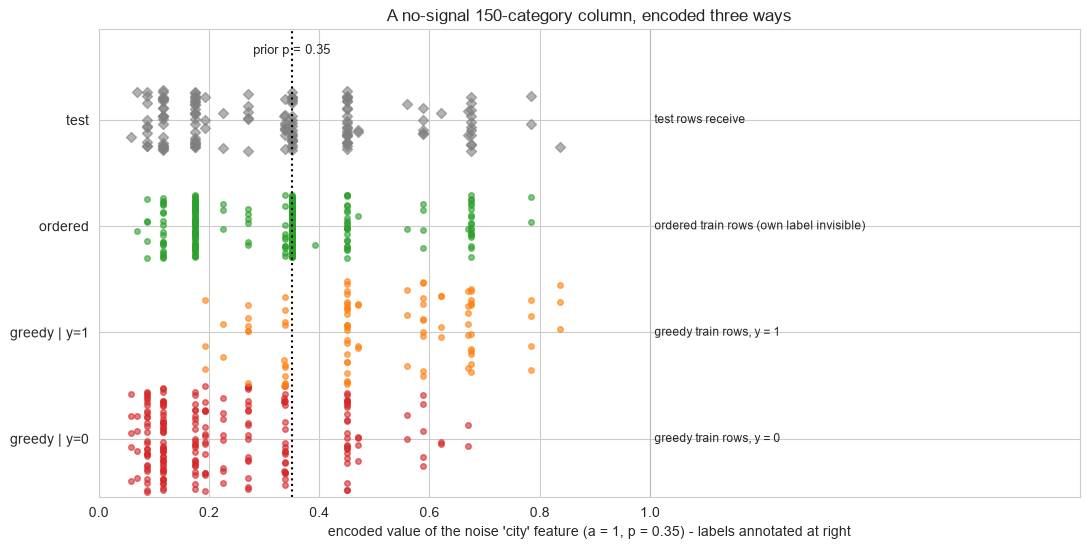

greedy band width: [0.0583, 0.8375] - and it is TWO bands,
  split by the row's own label: one split classifies the train set perfectly.
ordered band:         [0.0700, 0.7833]  (labels mixed regardless of y)
test band:            [0.0583, 0.8375]

💡 The two greedy bands separate the train rows by their OWN y - the leak, personified.
   The ordered band and the test band both hover around the prior instead: sampling
   noise on thin categories, but no label poles. The gap between the greedy training
   distribution and the test distribution is the conditional shift - and it is the
   one split that boosting will happily spend its first iteration on.


In [2]:
# One strip plot per view of the same no-signal categorical column
rng_v = np.random.default_rng(0)
n_v, n_cats_v, p_v, a_v = 300, 150, 0.35, 1.0        # prior = the base rate, a = the smoothing
city_v = rng_v.integers(0, n_cats_v, n_v)            # 150 unlabeled noise "cities" (~2 rows each)
y_v = (rng_v.random(n_v) < p_v).astype(int)          # labels ignore city entirely
perm_v = rng_v.permutation(n_v)                      # CatBoost's artificial "time" for ordered TS

# Greedy TS on train rows: per-category mean of y, own target included (Eq. 4, smoothed)
df_g = pd.DataFrame({"city": city_v, "y": y_v})
greedy_enc = df_g.groupby("city")["y"].transform(
    lambda s: (s.sum() + a_v * p_v) / (len(s) + a_v)).to_numpy()

# Ordered TS on train rows: only rows EARLIER in the permutation (same category) may vote
counts_v = np.zeros(n_cats_v)
sums_v = np.zeros(n_cats_v)
ordered_enc = np.zeros(n_v)
for r in range(n_v):
    i = perm_v[r]
    ordered_enc[i] = (sums_v[city_v[i]] + a_v * p_v) / (counts_v[city_v[i]] + a_v)
    counts_v[city_v[i]] += 1.0
    sums_v[city_v[i]] += y_v[i]

# Test rows: per-category statistics trained WITHOUT anyone's own target inside
# (D_k = D over the train rows, the same smoothed formula). Categories that drew NO
# training rows have no statistic to own - they fall back to the prior, which is
# exactly CatBoost's own prediction-time rule for unseen tiers.
test_map_v = df_g.groupby("city")["y"].apply(
    lambda s: (s.sum() + a_v * p_v) / (len(s) + a_v))
test_enc = np.array([test_map_v.get(c, p_v) for c in range(n_cats_v)])

jitter_v = rng_v.random(n_v) - 0.5
y_options_v = rng_v.random(n_cats_v) - 0.5

fig, ax_v = plt.subplots(figsize=(11, 5.6))
rows_v = [(0, "greedy train rows, y = 0", greedy_enc[y_v == 0],
           jitter_v[y_v == 0], "#d62728", "o", 16),
          (1, "greedy train rows, y = 1", greedy_enc[y_v == 1],
           jitter_v[y_v == 1], "#ff7f0e", "o", 16),
          (2, "ordered train rows (own label invisible)", ordered_enc,
           jitter_v * 0.6, "#2ca02c", "o", 16),
          (3, "test rows receive", test_enc, y_options_v * 0.6, "#7f7f7f",
           "D", 26)]
for y_row, label_v, xs_row, jl_row, color_row, mark_row, size_row in rows_v:
    ax_v.scatter(xs_row, np.full(len(xs_row), y_row) + jl_row, s=size_row, alpha=0.6,
                 color=color_row, marker=mark_row)
    ax_v.text(1.008, y_row, label_v, va="center", fontsize=8.6)
ax_v.axvline(p_v, color="black", ls=":", lw=1.5)
ax_v.axvline(1.0, color="#bbbbbb", ls="-", lw=0.8)
ax_v.text(p_v, 3.62, f"prior p = {p_v:g}", ha="center", fontsize=9)
ax_v.set_yticks([0, 1, 2, 3],
                ["greedy | y=0", "greedy | y=1", "ordered", "test"])
ax_v.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax_v.set_xlim(0, 1.78)
ax_v.set_ylim(-0.55, 3.85)
ax_v.set_xlabel("encoded value of the noise 'city' feature (a = 1, p = 0.35) "
                "- labels annotated at right")
ax_v.set_title(f"A no-signal {n_cats_v}-category column, encoded three ways")
plt.tight_layout()
plt.show()

print(f"greedy band width: [{greedy_enc.min():.4f}, {greedy_enc.max():.4f}] - and it is TWO bands,")
print(f"  split by the row's own label: one split classifies the train set perfectly.")
print(f"ordered band:         [{ordered_enc.min():.4f}, {ordered_enc.max():.4f}]  "
      f"(labels mixed regardless of y)")
print(f"test band:            [{test_enc.min():.4f}, {test_enc.max():.4f}]")
print("\n💡 The two greedy bands separate the train rows by their OWN y - the leak, personified.")
print("   The ordered band and the test band both hover around the prior instead: sampling")
print("   noise on thin categories, but no label poles. The gap between the greedy training")
print("   distribution and the test distribution is the conditional shift - and it is the")
print("   one split that boosting will happily spend its first iteration on.")

---

## 2. Theory & Mathematics

### The Same Leaf Algebra, Priced by Default

Notebook 08's derivation carries through the whole library family: at stage $m$ the loss is second-order Taylor-expanded around the current model, and the optimal Newton leaf value and the candidate-split gain are closed forms over $(G, H)$ per leaf:

$$w_j^* = -\frac{G_j}{H_j + \lambda} \qquad \mathrm{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} — \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right]$$

with $g_i = \partial \ell / \partial \hat{y}$, $h_i = \partial^2 \ell / \partial \hat{y}^2$ at the current prediction (log-loss: $g = p - y$, $h = p(1-p)$ — the notebook-09 table). CatBoost's two default differences versus the previous chapters:

1. **λ ships at 3, not 0** — `l2_leaf_reg` is the native spelling of the same $\lambda$ inside $w^* = -G/(H+\lambda)$ (XGBoost ships 1, LightGBM ships 0). Smoothing is on the moment the model is created
2. **The leaf value procedure is iterative** — `leaf_estimation_method` (`Newton` for the classification losses, `Gradient` — a plain mean-style step — for the RMSE-regressor, per the docs' parameter reference) runs `leaf_estimation_iterations` refinement rounds per stage (10 for the classification losses, 1 for RMSE). The hand engines below compute the one-round Newton value; the library converges the same quantity a few steps further

In [3]:
# One leaf's five training samples - the same numbers as notebooks 08/09/10's demo leaf,
# now under CatBoost's reading: the shipped l2_leaf_reg = 3 is a REAL default
p_leaf = np.array([0.90, 0.20, 0.40, 0.70, 0.60])   # current probabilities
y_leaf = np.array([1.0, 1.0, 0.0, 1.0, 0.0])        # true labels

g_leaf = p_leaf - y_leaf               # first-order term (library sign: p - y)
h_leaf = p_leaf * (1.0 - p_leaf)       # its curvature: p(1 - p)

G_leaf, H_leaf = g_leaf.sum(), h_leaf.sum()
print(f"leaf sums:  G = sum(g) = {G_leaf:+.4f}   H = sum(h) = {H_leaf:.4f}")

print()
for lam_l in [0.0, 3.0, 10.0]:
    w_l = -G_leaf / (H_leaf + lam_l)
    print(f"leaf value w* at l2_leaf_reg = {lam_l:5.1f}: {w_l:+.4f}"
          f"{'   <- CatBoost ships this' if lam_l == 3.0 else ''}")

# The same gain the family scores candidates with (at the shipped lambda = 3)
big_l = np.array([1, 2]); rest_l = np.array([0, 3, 4])
G_left = g_leaf[big_l].sum();  H_left = h_leaf[big_l].sum()
G_right = g_leaf[rest_l].sum(); H_right = h_leaf[rest_l].sum()
gain_l = 0.5 * (G_left**2 / (H_left + 3.0) + G_right**2 / (H_right + 3.0)
                - G_leaf**2 / (H_leaf + 3.0))
print(f"\nsplit gain at lambda = 3 (a candidate priced at the shipped default): {gain_l:.4f}")

print("\n💡 Identical algebra to notebooks 08-10 - the leaf value is still -G/(H + lambda).")
print("   The chapter shift is not the leaf: it is WHERE g_i comes from. In the classic")
print("   family g_i is computed by the very model that watched row i be trained; CatBoost")
print("   replaces that with a prefix-model estimate (section 5) before any split is priced.")

leaf sums:  G = sum(g) = -0.2000   H = sum(h) = 0.9400

leaf value w* at l2_leaf_reg =   0.0: +0.2128
leaf value w* at l2_leaf_reg =   3.0: +0.0508   <- CatBoost ships this
leaf value w* at l2_leaf_reg =  10.0: +0.0183

split gain at lambda = 3 (a candidate priced at the shipped default): 0.0241

💡 Identical algebra to notebooks 08-10 - the leaf value is still -G/(H + lambda).
   The chapter shift is not the leaf: it is WHERE g_i comes from. In the classic
   family g_i is computed by the very model that watched row i be trained; CatBoost
   replaces that with a prefix-model estimate (section 5) before any split is priced.


### Target Statistics: Greedy vs Ordered

The paper's two formulas, verbatim. The **greedy** target statistic smooths a category's mean target toward a prior $p$ with weight $a$:

$$\hat{x}^{(i)}_k = \frac{\sum_{j=1}^{n} \mathbb{1}\{x^{(i)}_j = x^{(i)}_k\}\, y_j + a\,p}{\sum_{j=1}^{n} \mathbb{1}\{x^{(i)}_j = x^{(i)}_k\} + a}$$

Smoothing tames noise for tiny categories; it does **not** remove leakage, because $y_k$ still sits inside the numerator. The fix is to exclude the row itself — take $\mathcal{D}_k \subset \mathcal{D} \setminus \{\mathbf{x}_k\}$ and compute Eq. (5) on that subset:

$$\hat{x}^{(i)}_k = \frac{\sum_{\mathbf{x}_j \in \mathcal{D}_k} \mathbb{1}\{x^{(i)}_j = x^{(i)}_k\}\, y_j + a\,p}{\sum_{\mathbf{x}_j \in \mathcal{D}_k} \mathbb{1}\{x^{(i)}_j = x^{(i)}_k\} + a}$$

The property the paper states for this is **P1**: $\mathbb{E}(\hat{x}^{(i)} \mid y = v) = \mathbb{E}(\hat{x}^{(i)}_k \mid y_k = v)$ — the *statistics* a test row receives must match what a training row that happens to carry label $v$ sees. The **ordered** choice achieves P1 while still using every training row: draw a random permutation $\sigma$ (an artificial time), take $\mathcal{D}_k = \{\mathbf{x}_j : \sigma(j) < \sigma(k)\}$ on training rows and $\mathcal{D}_k = \mathcal{D}$ on test rows. The documentation's implementation formula

$$ctr = \frac{\mathrm{countInClass} + \mathrm{prior}}{\mathrm{totalCount} + 1}$$

is the same object in its unit-smoothing dress — one pseudo-row of prior voted in; CatBoost in fact sweeps *several* prior-configured variants per permutation and uses them in the split search (`simple_ctr`, `combinations_ctr`). Two refinements ship alongside:

- **Permutations, plural**: one permutation makes early rows' statistics too noisy — CatBoost maintains a family of permutations and rotates through them across the stage budget
- **Combinations**: `max_ctr_complexity` (default 4) lets the encoder build statistics over *pairs/triples* of categorical (and quantized-float × categorical) features — "tier × has-android" as one column — before the trees ever see them

The toy table below executes the formulas by hand on six rows and three cities, permutation included.

In [4]:
# The paper's formulas, worked by hand on a toy table
toy_v = pd.DataFrame({
    "row":  [0, 1, 2, 3, 4, 5],
    "city": ["A", "A", "B", "C", "B", "C"],
    "y":    [1, 1, 0, 1, 0, 0],
})
a_toy, p_toy, perm_toy = 1.0, 0.5, [2, 0, 3, 1, 5, 4]   # visit order: rows B, A, C, A, C, B

# Greedy: full-data per-category means (own y included), smoothed by a
greedy_toy = toy_v.groupby("city")["y"].apply(lambda s: (s.sum() + a_toy * p_toy) / (len(s) + a_toy))
print(f"greedy encodings:  A -> {greedy_toy['A']:.4f}   B -> {greedy_toy['B']:.4f}   "
      f"C -> {greedy_toy['C']:.4f}")

# Ordered: walk the permutation; vote only with previously-seen rows of the same city
seen_votes_toy = {}
rows_os = []
for r_toy, row_id in enumerate(perm_toy):
    city_id = toy_v.loc[row_id, "city"]
    cnt_toy, sum_toy = seen_votes_toy.get(city_id, (0, 0.0))
    val_toy = (sum_toy + a_toy * p_toy) / (cnt_toy + a_toy)
    rows_os.append((row_id, city_id, toy_v.loc[row_id, "y"], val_toy, cnt_toy))
    seen_votes_toy[city_id] = (cnt_toy + 1, sum_toy + toy_v.loc[row_id, "y"])

print("\nordered walk (permutation " + str(perm_toy) + "):")
for row_id, city_id, y_row, val_toy, cnt_toy in rows_os:
    where_toy = f"{cnt_toy:g} prior row(s)" if cnt_toy else "no history yet"
    print(f"  visit row {row_id} (city {city_id}, y = {y_row}): enc = {val_toy:.4f}  "
          f"[{where_toy}; prior p = {p_toy:g}]")

print(f"\ntest rows would receive the full-train statistics the same way the greedy table "
      f"encodes them: A = {greedy_toy['A']:.4f}, B = {greedy_toy['B']:.4f}, "
      f"C = {greedy_toy['C']:.4f}")
print("\n💡 Row 4 (city B, y = 0) is the property P1 in action: its encode 0.25 was earned")
print("   from row 2's target ALONE - flip row 4's own label and its own encode does not")
print("   move. The greedy encoding of city B (0.1667) instead folds BOTH targets in -")
print("   every row's feature already knows its own answer. Ordering is the difference.")

greedy encodings:  A -> 0.8333   B -> 0.1667   C -> 0.5000

ordered walk (permutation [2, 0, 3, 1, 5, 4]):
  visit row 2 (city B, y = 0): enc = 0.5000  [no history yet; prior p = 0.5]
  visit row 0 (city A, y = 1): enc = 0.5000  [no history yet; prior p = 0.5]
  visit row 3 (city C, y = 1): enc = 0.5000  [no history yet; prior p = 0.5]
  visit row 1 (city A, y = 1): enc = 0.7500  [1 prior row(s); prior p = 0.5]
  visit row 5 (city C, y = 0): enc = 0.7500  [1 prior row(s); prior p = 0.5]
  visit row 4 (city B, y = 0): enc = 0.2500  [1 prior row(s); prior p = 0.5]

test rows would receive the full-train statistics the same way the greedy table encodes them: A = 0.8333, B = 0.1667, C = 0.5000

💡 Row 4 (city B, y = 0) is the property P1 in action: its encode 0.25 was earned
   from row 2's target ALONE - flip row 4's own label and its own encode does not
   move. The greedy encoding of city B (0.1667) instead folds BOTH targets in -
   every row's feature already knows its own answer. Orde

### Oblivious Trees: One Condition per Level

XGBoost grows level-balanced trees, LightGBM spends a leaf budget greedily; CatBoost grows trees **level-symmetric** — every node at depth $d$ shares the same split condition. A depth-$d$ oblivious tree is $2^d$ leaves split by $d$ conditions, applied in the exact order of their levels:

$$\mathrm{leaf}(x) = \sum_{\ell=0}^{d-1} \mathbb{1}\{x_{f_\ell} > t_\ell\}\, 2^{\,d-1-\ell}$$

— the leaf index literally *is* the binary string of yes/no answers. The per-level condition is chosen by scoring every candidate $(f, t)$ against **every open node** of the level and keeping the pair with the largest summed gain. The structural consequences, read straight off the shape:

| | Oblivious tree (depth $d$) | Free tree (same budget) |
|---|---|---|
| conditions stored | exactly $d$ | up to $2^d - 1$ |
| parameters to fit | $d$ conditions + $2^d$ leaf values | per-node conditions + ~$2^{d+1}$ leaves |
| shape freedom | none — one test per level | full — every subtree its own tests |
| overfitting surface | shallow: asymmetry cannot form | the greedy leaf-chasing failure modes |

`max_depth` caps $d$ at 16; `grow_policy` (`SymmetricTree` default, `Depthwise`, `Lossguide` — the last one is LightGBM-style best-first) exists for analysts who want the other two shapes, at the cost of CatBoost's structural regularization story.

When a categorical column is inside a tree, its ordered statistics land there as one numeric column; splits in an oblivious level are ordinary borders on those columns (or on the 254 `border_count`-binned floats).

### Ordered Boosting: The Gradient Estimates Themselves

Even with honest statistics, one bias survives: gradients are computed from a model $F$ that was **trained on the same rows** the tree will be fitted on. The paper's direct repair maintains, per permutation, auxiliary models $M_r$ trained on the first $r$ rows only — the gradient for the row at rank $r$ is read from $M_{r-1}$, which has never seen that row. The shipped engine keeps the idea intact through the tech report's relaxation, which this notebook will implement as-is in §5:

- the auxiliary models **share tree structures** — one structural decision per stage, built on the ordered estimates
- each prefix model keeps its **own leaf values** on that structure, from its own rows
- the prefix set is the **power-of-two relaxation**: a row of rank $r$ reads its gradient from the model trained on the first $2^{\lfloor \log_2 r \rfloor}$ rows — $\log_2 n$ auxiliary models instead of $n$, and one tree's worth of bookkeeping at $O(n)$ instead of $O(n^2)$

---

## 3. Assumptions & Requirements

CatBoost inherits the tree base learner's distributional freedom and the boosting assumptions of notebooks 08–10 — then adds a headline feature of its own and one machinery-specific requirement.

### Critical Assumptions

#### ✅ 1. **No Feature Scaling Needed**
- Splits compare one feature against a border; monotone rescaling never changes an ordering — true of the whole tree family (notebooks 03–10)
- **Contrast**: SVMs, KNN, and logistic regression all need scaling (notebooks 05–07)

#### ✅ 2. **Strings Must Be Declared or Encoded** *(the machinery-specific requirement)*
- CatBoost reads only numbers, one-hot-encodable integers, and the categories you *declare* in `cat_features` — an undeclared string column is a loud error, not a silent numeric fold
- Declared categoricals travel through the ordered-TS machinery automatically — including **NaNs, which become the string "None"** and are treated as their own category
- Float features carry their own NaN route natively (`nan_mode`, default Min on CPU: missing values ride the lower border of their splits) — the histogram family's no-imputer promise, one chapter later

#### ✅ 3. **The Rows Must Be Exchangeable** *(the ordering machinery's assumption)*
- Permutations treat all rows as statistically equal; a drifted, ordered-in-time dataset violates the exchangeability the permuted statistics subsample from
- `has_time=True` (use input order instead of permutations) or a deliberate time-aware split handles it — as every earlier notebook said: time handling stays your job

#### ✅ 4. **The Loss Must Match the Task**
- `loss_function` (Logloss, CrossEntropy, MultiClass; RMSE, MAE, Quantile, Huber, ...) is inferred by the wrapper's class; `eval_metric` is your call and drives early stopping — a wrong metric quietly optimizes the wrong decision (§7/§9)

#### ✅ 5. **Enough Rows for the Defaults to Mean Anything**
- `depth = 6` is 64 leaves per stage tree — honest only when leaves receive rows; `min_data_in_leaf` exists (alias `min_child_samples`) but unlike LightGBM's story, the shipped defaults lean on `l2_leaf_reg = 3` and `random_strength` to keep the deeper levels honest
- `boosting_type=Ordered` is expensive (≈$\log_2 n$ auxiliary models per stage) — the budget auto-switch targets exactly where Ordered's benefit lives (small data)

### When Assumptions Are Violated

| Violation | Symptom | Fix |
|---|---|---|
| Noisy targets, greedy-style encodings forced in | Train accuracy far above validation; test loss curls up | Keep ordered TS (the default); raise `l2_leaf_reg`; `iterations` down; early stopping (§7) |
| High-cardinality categorical, few rows per value | Rare categories pull predictions on single-row evidence | The CTR priors damp them; watch the train-test gap (§3's demo); aggregate rare tiers deliberately |
| Class imbalance | Accuracy hides a bad minority recall | `auto_class_weights="Balanced"` (or `scale_pos_weight`), per-class metrics |
| Extrapolation required | Predictions clamp to the training range | Linear or Gaussian-process models (notebook 01) |
| Undeclared string columns | Fit fails loudly with a type error | Declare `cat_features` — or encode deliberately (ordered TS *is* the in-box encoding) |
| Time-ordered, drifted data | Permuted statistics borrow from the future | `has_time=True`, or a deliberate time-aware split |

### The NaN Demo: `nan_mode` Routing, One Chapter Later

Notebook 10's missingness probe, re-run for the third engine: the same breast-cancer matrix with 10% of its cells set to NaN, straight into the engine — plus the honest control rows (median imputation) so "native routing works" is measured, not asserted. For CatBoost the float NaNs ride `nan_mode` (default Min: a NaN takes the lower side of its splits); a **categorical** NaN would instead become the string `"None"` — its own category, not an error.

rows in train: 426, cells set to NaN: 1311/12780
CatBoost on NaN train data:           test acc 95.1%  |  clean test acc 96.5%
HistGradientBoosting on NaN data:     test acc 96.5%
sklearn GradientBoostingClassifier:   ValueError - refuses NaN, imputation required


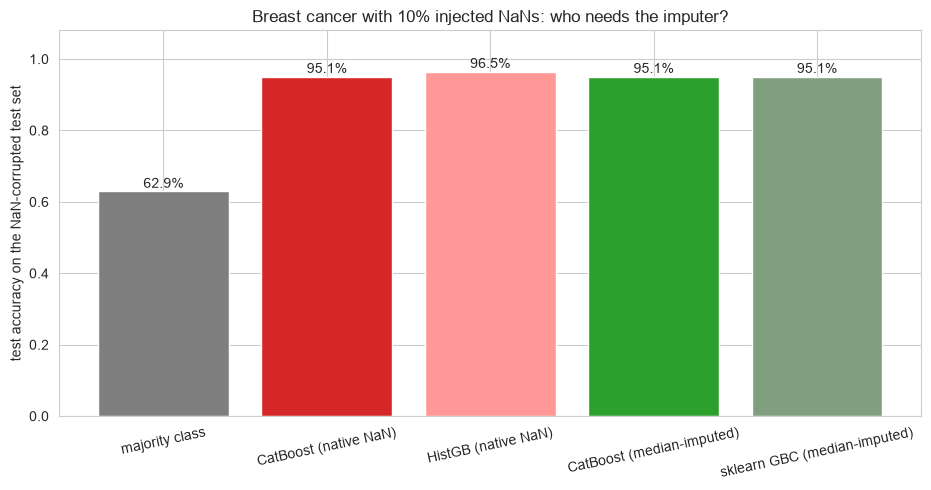


💡 Third chapter, same verdict: the compiled engines learn where NaNs belong instead
   of mailing them to an imputer. For CatBoost the float story is nan_mode (Min by
   default); the CATEGORICAL story is different - a missing category becomes the
   string 'None' and competes as its own tier. No cell ever gets dropped.


In [5]:
# The section 3 demo, part 1: float NaN routing - CatBoost natively, siblings beside it
bc_nan = load_breast_cancer()
Xbn_tr, Xbn_te, ybn_tr, ybn_te = train_test_split(
    bc_nan.data, bc_nan.target, test_size=0.25, stratify=bc_nan.target, random_state=42
)

# Inject 10% missingness - independently per cell, train and test
rng_nan = np.random.default_rng(0)
nan_mask_tr = rng_nan.random(Xbn_tr.shape) < 0.10
nan_mask_te = rng_nan.random(Xbn_te.shape) < 0.10
Xbn_tr_nan = Xbn_tr.copy()
Xbn_tr_nan[nan_mask_tr] = np.nan
Xbn_te_nan = Xbn_te.copy()
Xbn_te_nan[nan_mask_te] = np.nan
print(f"rows in train: {len(Xbn_tr)}, cells set to NaN: {nan_mask_tr.sum()}/{Xbn_tr.size}")

cb_nan = CatBoostClassifier(n_estimators=150, learning_rate=0.1, depth=4,
                            verbose=False, random_state=42).fit(Xbn_tr_nan, ybn_tr)
hist_nan = HistGradientBoostingClassifier(max_depth=3, random_state=42).fit(Xbn_tr_nan, ybn_tr)

print(f"CatBoost on NaN train data:           test acc {cb_nan.score(Xbn_te_nan, ybn_te):.1%}"
      f"  |  clean test acc {cb_nan.score(Xbn_te, ybn_te):.1%}")
print(f"HistGradientBoosting on NaN data:     test acc {hist_nan.score(Xbn_te_nan, ybn_te):.1%}")

try:
    GradientBoostingClassifier(n_estimators=150).fit(Xbn_tr_nan, ybn_tr)
    print("sklearn GradientBoostingClassifier:   fitted (unexpected)")
except ValueError:
    print("sklearn GradientBoostingClassifier:   ValueError - refuses NaN, imputation required")

# Control rows: median imputation repairs the plain sklearn engine, and CatBoost itself
# barely changes - the routing is already the imputation that matters
cb_imputed = Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("cb", CatBoostClassifier(n_estimators=150, learning_rate=0.1, depth=4,
                                                 verbose=False, random_state=42))]).fit(Xbn_tr_nan, ybn_tr)
gbc_imputed = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("gb", GradientBoostingClassifier(n_estimators=150,
                                                          random_state=42))]).fit(Xbn_tr_nan, ybn_tr)

majority_nan = max(np.bincount(ybn_te)) / len(ybn_te)
rows_nan = [
    ("majority class", majority_nan),
    ("CatBoost (native NaN)", cb_nan.score(Xbn_te_nan, ybn_te)),
    ("HistGB (native NaN)", hist_nan.score(Xbn_te_nan, ybn_te)),
    ("CatBoost (median-imputed)", cb_imputed.score(Xbn_te_nan, ybn_te)),
    ("sklearn GBC (median-imputed)", gbc_imputed.score(Xbn_te_nan, ybn_te)),
]

fig, ax = plt.subplots(figsize=(9.5, 5))
labels_nan = [name_nan for name_nan, _ in rows_nan]
vals_nan = [v_nan for _, v_nan in rows_nan]
ax.bar(labels_nan, vals_nan, color=["#7f7f7f", "#d62728", "#ff9896", "#2ca02c", "#7f9f7f"])
for i_nan, v_nan in enumerate(vals_nan):
    ax.text(i_nan, v_nan + 0.01, f"{v_nan:.1%}", ha="center")
ax.set_ylim(0, 1.08)
ax.set_ylabel("test accuracy on the NaN-corrupted test set")
ax.set_title("Breast cancer with 10% injected NaNs: who needs the imputer?")
ax.tick_params(axis="x", labelrotation=12)
plt.tight_layout()
plt.show()

print("\n💡 Third chapter, same verdict: the compiled engines learn where NaNs belong instead")
print("   of mailing them to an imputer. For CatBoost the float story is nan_mode (Min by")
print("   default); the CATEGORICAL story is different - a missing category becomes the")
print("   string 'None' and competes as its own tier. No cell ever gets dropped.")

### The Categorical Demo: Where the Statistic Comes From Decides Where the Model Overfits

CatBoost's flagship assumption, made empirical. Synthetic churn data with the annoying parts intact — a non-monotone real `tier` signal, two weak numerics — plus a **no-signal high-cardinality `city` column** (150 values, ≈2–3 rows each, zero target effect: the leak magnet). The same family twin trains three times on the same rows, differing ONLY in how `city` arrived:

1. **greedy TS** — full-train per-category target means, own row's target inside (the leaky standard)
2. **ordered TS** — the causal walk of §2 (only earlier rows vote), full-train statistics on test rows
3. **one-hot** — 40 indicator columns, the encoding CatBoost's paper argues against

The twin is the shared engine here, so the encodings — not the booster — own every difference.

      city encoding  train acc  test acc  train-test gap
  greedy TS (leaky)     0.9175     0.580          0.3375
ordered TS (causal)     0.8050     0.635          0.1700
       one-hot city     0.8225     0.665          0.1575

mean |encoded value - own label| on train rows, per encoding:
  greedy : 0.2847   (the leak, quantified)
  ordered: 0.4536


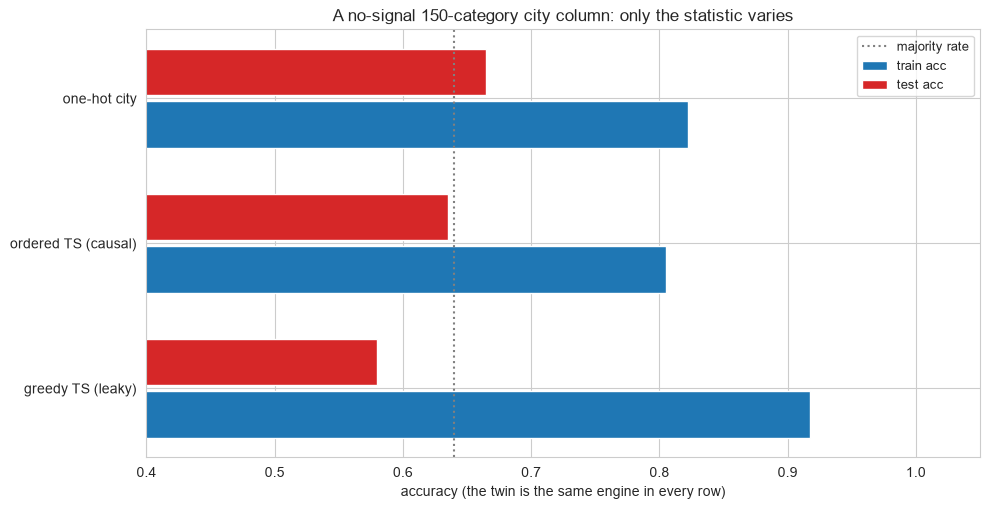


💡 Only the greedy encoding's TRAIN accuracy runs away from its test accuracy -
   the leak: train rows' features carry their own label, test rows' features cannot.
   Ordered TS and one-hot keep the two columns aligned because their train-row
   statistics contain no self-target. City itself is pure noise in every row, so
   the TEST column stays near the baseline everywhere - what the leak changes is
   how much of the model's capacity gets WASTED pretending city mattered.


In [6]:
# The section 3 demo, part 2: the leak measured through one fixed engine
rng_cat = np.random.default_rng(7)
n_tr, n_te, n_city = 400, 200, 150

cities_tr = rng_cat.integers(0, n_city, n_tr)
cities_te = rng_cat.integers(n_city, 2 * n_city, n_te)   # test cities ALL unseen
tiers_cat = rng_cat.choice(["free", "basic", "plus", "premium", "partner"],
                           n_tr + n_te, p=[0.30, 0.25, 0.20, 0.18, 0.07])
tier_effect_cat = {"free": 0.45, "basic": -0.30, "plus": 0.35,
                   "premium": -0.90, "partner": -1.20}
tenure_cat = rng_cat.exponential(14.0, n_tr + n_te)
logins_cat = rng_cat.poisson(3, n_tr + n_te)

logit_cat = (np.array([tier_effect_cat[t] for t in tiers_cat])
             - 0.06 * tenure_cat + 0.40 * np.log1p(np.log1p(logins_cat))
             + rng_cat.normal(0.0, 0.55, n_tr + n_te))
churn_cat = (1.0 / (1.0 + np.exp(-logit_cat)) > rng_cat.random(n_tr + n_te)).astype(int)

a_leak, p_leak = 1.0, float(churn_cat[:n_tr].mean())     # smoothing a, prior p (train base rate)

y_tr_arr = churn_cat[:n_tr].astype(float)

# GREEDY: train encodes include the row's own target (per-category target mean)
enc_greedy_tr = pd.Series(y_tr_arr).groupby(cities_tr).mean().loc[cities_tr].to_numpy()

# ORDERED: causal walk on train - only earlier permuted rows of the same city may vote
counts_lk, sums_lk = np.zeros(n_city), np.zeros(n_city)
enc_ordered_tr = np.zeros(n_tr)
perm_lk = rng_cat.permutation(n_tr)
for r in range(n_tr):
    i = perm_lk[r]
    enc_ordered_tr[i] = (sums_lk[cities_tr[i]] + a_leak * p_leak) / (counts_lk[cities_tr[i]] + a_leak)
    counts_lk[cities_tr[i]] += 1.0
    sums_lk[cities_tr[i]] += y_tr_arr[i]

# Test rows (both encodings): the full-train per-category statistic, unseen -> prior p
enc_full_map = pd.Series(y_tr_arr).groupby(cities_tr).apply(
    lambda s: (s.sum() + a_leak * p_leak) / (len(s) + a_leak))
enc_full_te = enc_full_map.reindex(cities_te).fillna(p_leak).to_numpy().reshape(-1, 1)

tier_codes = pd.Categorical(tiers_cat, categories=list(tier_effect_cat))
tier_oh_all = np.eye(len(tier_effect_cat))[tier_codes.codes.astype(int)]

tier_oh_tr = tier_oh_all[:n_tr]
tier_oh_te = tier_oh_all[n_tr:]
tenure_tr = tenure_cat[:n_tr].reshape(-1, 1); logins_tr = logins_cat[:n_tr].reshape(-1, 1)
tenure_te = tenure_cat[n_tr:].reshape(-1, 1); logins_te = logins_cat[n_tr:].reshape(-1, 1)

variants_leak = {
    "greedy TS (leaky)": np.hstack([enc_greedy_tr.reshape(-1, 1), tier_oh_tr, tenure_tr, logins_tr]),
    "ordered TS (causal)": np.hstack([enc_ordered_tr.reshape(-1, 1), tier_oh_tr, tenure_tr, logins_tr]),
    "one-hot city": np.hstack([np.eye(n_city)[cities_tr], tier_oh_tr, tenure_tr, logins_tr]),
}
tests_leak = {
    "greedy TS (leaky)": np.hstack([enc_full_te, tier_oh_te, tenure_te, logins_te]),
    "ordered TS (causal)": np.hstack([enc_full_te, tier_oh_te, tenure_te, logins_te]),
    "one-hot city": np.hstack([np.zeros((n_te, n_city)), tier_oh_te, tenure_te, logins_te]),
}

rows_leak = []
for name_v, Xc_tr in variants_leak.items():
    twin_lk = GradientBoostingClassifierScratch(n_estimators=60, learning_rate=0.1,
                                                max_depth=3).fit(Xc_tr, churn_cat[:n_tr])
    acc_tr_v = twin_lk.score(Xc_tr, churn_cat[:n_tr])
    acc_te_v = twin_lk.score(tests_leak[name_v], churn_cat[n_tr:])
    rows_leak.append({"city encoding": name_v, "train acc": acc_tr_v,
                      "test acc": acc_te_v, "train-test gap": acc_tr_v - acc_te_v})

df_leak = pd.DataFrame(rows_leak)
print(df_leak.round(4).to_string(index=False))
print(f"\nmean |encoded value - own label| on train rows, per encoding:")
print(f"  greedy : {np.abs(enc_greedy_tr - y_tr_arr).mean():.4f}   (the leak, quantified)")
print(f"  ordered: {np.abs(enc_ordered_tr - y_tr_arr).mean():.4f}")

fig, ax_lk = plt.subplots(figsize=(10, 5.2))
ypos_lk = np.arange(len(df_leak))
ax_lk.barh(ypos_lk - 0.18, df_leak["train acc"], height=0.32, color="#1f77b4", label="train acc")
ax_lk.barh(ypos_lk + 0.18, df_leak["test acc"], height=0.32, color="#d62728", label="test acc")
ax_lk.axvline(max(np.bincount(churn_cat)) / (n_tr + n_te), color="gray",
              ls=":", lw=1.5, label="majority rate")
ax_lk.set_yticks(ypos_lk, df_leak["city encoding"])
ax_lk.set_xlim(0.4, 1.05)
ax_lk.set_xlabel("accuracy (the twin is the same engine in every row)")
ax_lk.set_title(f"A no-signal {n_city}-category city column: only the statistic varies")
ax_lk.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("\n💡 Only the greedy encoding's TRAIN accuracy runs away from its test accuracy -")
print("   the leak: train rows' features carry their own label, test rows' features cannot.")
print("   Ordered TS and one-hot keep the two columns aligned because their train-row")
print("   statistics contain no self-target. City itself is pure noise in every row, so")
print("   the TEST column stays near the baseline everywhere - what the leak changes is")
print("   how much of the model's capacity gets WASTED pretending city mattered.")

---

## 4. When to Use This Algorithm

### ✅ Use CatBoost When:

1. **The table has real categorical columns**
    — Declare them in `cat_features`; ordered statistics, prior smoothing, and cross-feature combinations (`max_ctr_complexity`) are the engine's home turf — no hand-built encoding pipeline on the critical path (§3's demo priced what each encoding costs)
2. **Small-to-medium data (up to ~50k rows)**
    — `boosting_type=Ordered` is the automatic default in exactly that range: the self-fitted gradients of classic boosting overfit small data fastest, and ordered estimates are the direct repair
3. **Defaults matter more than a tuning session**
    — `l2_leaf_reg = 3`, `random_strength = 1`, `border_count = 254`, oblivious depth 6: the shipped configuration comes pre-regularized — the family's "install and it is reasonable" member (§6)
4. **Regression on structured data too**
    — `CatBoostRegressor` with objectives from RMSE to MAE, Quantile, Huber, Poisson
5. **Probability-like outputs on decision-critical tasks**
    — The same verification as notebooks 08/09/10's Example 1: reliability histograms + Brier score before decisions (§10)
6. **Portable production model artifacts**
    — `save_model`/`load_model` on a self-describing `.cbm` file; JSON export without extra packages

### ❌ Avoid CatBoost When:

1. **Very large datasets where training time is the product**
    — Ordered boosting's per-round multi-model bookkeeping is the slowest lane of the three libraries (the docs' speed-up page says it straight: switch to `Plain` on big data); LightGBM owns the raw-throughput crown (§11)
2. **A few hundred rows with untouched defaults**
    — `depth = 6` is 64 leaves per stage; on tiny data shrink `depth` deliberately, or a single pruned tree is steadier (notebooks 01–03)
3. **Extrapolation is required**
    — Trees clamp to the training range; nothing boosted extrapolates (§10's Example 2)
4. **A small, audit-walkable model must be deployed**
    — Oblivious trees are *structurally* simple (§2), but a thousand-stage ensemble is not walkable leaf by leaf; `plot_tree` needs graphviz — explainability is post-hoc (SHAP, §6), not a tour
5. **You need calibrated probabilities with no verification step**
    — Confident-but-wrong is the failure mode of any boosted probability; check the Brier read first (§10)
6. **Text/image-adjacent unstructured data**
    — Representation learning owns that world (notebook 17)

### Classification vs Regression

| | Classification | Regression |
|---|---|---|
| Estimator | `CatBoostClassifier` | `CatBoostRegressor` |
| Default objective | auto: `Logloss` / `MultiClass` | auto: `RMSE` |
| $g_i$, $h_i$ | $p - y$; $p(1-p)$ (per class, MultiClass) | $F - y$; $1$ (squared-error gradients) |
| Leaf estimation | `Newton` × `leaf_estimation_iterations` (10) | `Gradient` × 1 (RMSE, per the docs' parameter reference) |
| Trees per stage | 1 (binary), K (`MultiClass`) | 1 |
| Ordered default | ≤ 50k objects, CPU, non-MultiClass → `Ordered` | same rule |
| Stage budget | `iterations` (aliases `n_estimators`, `num_boost_round`) | same |
| From-scratch twin | family twin `GradientBoostingClassifierScratch` (§5) | none — library-only (§6) |

---

## 5. Implementation from Scratch (NumPy)

### Why Hands-On, When CatBoost Itself Is Compiled?

CatBoost *the library* is a compiled C++/GPU system — the repo does not (and should not) re-implement that part. What the repo does implement is the **gradient boosting skeleton** all three libraries build on: `GradientBoostingClassifierScratch` in `src/models/ensemble_models.py`, the notebook-08 twin with its Newton leaf values (notebooks 09–10 showed `_newton_leaf_values` is exactly $w^* = -G/(H+\lambda)$ at λ = 0).

Section 5 uses that twin as the reference point and hand-builds CatBoost's three defining moves on top of it:

1. **The ordered target-statistics encoder** — Eq. (5) with the permutation walk, in NumPy: prior $p$, smoothing weight $a$, no self-target anywhere — validated against §2's toy table, then swept over the smoothing knob on §3's leak-magnet data
2. **The oblivious (symmetric) tree grower** — CatBoost's long-loop grower, in NumPy: per-level candidate grids priced on the gain formula summed over the level's nodes, one shared condition per level, leaf values as a separate Newton phase — with **both pricings on one code path** (the gain pricing for the engine, the twin-faithful variance pricing for a bit-for-bit reference check at depth 1)
3. **A prefix-model ordered boosting loop** — the paper's Algorithm 1 with the tech report's own relaxation: $\log_2 n$ auxiliary models over one permutation, a row of rank $r$ reading its gradient from the model trained on the first $2^{\lfloor \log_2 r \rfloor}$ rows; tree structures shared, leaf values per prefix model. The `ordered=False` branch collapses every source to the full model — the classic loop — so ordered-vs-plain is one flag on one code path

What is deliberately **not** hand-built here: the multi-permutation pools and their rotation, CTR feature combinations, NaN-aware border computation, the compiled execution, and the GPU paths. Those coordinates get discussed where they matter (§2, §6, §8) but never re-computed.

In [7]:
# The family twin is already imported (section 1's imports cell).
# This banner records what section 5 hand-builds on top of it.

print("✅ Family twin in scope:", GradientBoostingClassifierScratch.__name__,
      "from src/models/ensemble_models.py (also its stage trees:",
      DecisionTreeRegressorScratch.__name__ + ")")
print("\nWhat the twin provides (guided in notebooks 08/09/10, section 5 there):")
print("  • stagewise additive model on log-loss / softmax deviance")
print("  • F0 = the log-odds of the positive base rate (_f0_logit)")
print("  • stage trees: residual least squares + Newton leaf values sum(g)/sum(h)")
print("  • shrinkage once per stage; prediction replays the stages (_decision)")
print("\nWhat notebook 11 hand-builds on top of it (the CatBoost-specific moves):")
print("  • ordered_ts_encode / greedy_ts_encode: Eq. (5) + the permutation walk")
print("  • grow_oblivious: level-shared conditions, per-level priced candidates,")
print("    Newton leaf values w* = -G/(H + lambda) as a separate phase")
print("  • ordered_cat_boost: power-of-two prefix models estimating gradients,")
print("    shared structures, per-prefix leaf values, ordered=False = plain boosting")
print("\nWhat is NOT re-implemented (the compiled engine handles these):")
print("  • the multi-permutation pools and their rotation, CTR feature combinations,")
print("    GPU border paths, and the C++ execution of every stage")

✅ Family twin in scope: GradientBoostingClassifierScratch from src/models/ensemble_models.py (also its stage trees: DecisionTreeRegressorScratch)

What the twin provides (guided in notebooks 08/09/10, section 5 there):
  • stagewise additive model on log-loss / softmax deviance
  • F0 = the log-odds of the positive base rate (_f0_logit)
  • stage trees: residual least squares + Newton leaf values sum(g)/sum(h)
  • shrinkage once per stage; prediction replays the stages (_decision)

What notebook 11 hand-builds on top of it (the CatBoost-specific moves):
  • ordered_ts_encode / greedy_ts_encode: Eq. (5) + the permutation walk
  • grow_oblivious: level-shared conditions, per-level priced candidates,
    Newton leaf values w* = -G/(H + lambda) as a separate phase
  • ordered_cat_boost: power-of-two prefix models estimating gradients,
    shared structures, per-prefix leaf values, ordered=False = plain boosting

What is NOT re-implemented (the compiled engine handles these):
  • the multi-

### The Ordered Target-Statistics Encoder (Hand-Built)

Three functions, one contract each:

- `greedy_ts_encode(values, y, prior, a)` — Eq. (4): per-category full-data means, **own target inside**. Included only so the leak has a named villain
- `ordered_ts_encode(values, y, permutation, prior, a)` — Eq. (5) + ordering: the permutation walk of §2's toy in NumPy; no row's own $y_k$ can ever touch its own encode
- `full_ts_map(values, y, prior, a)` — the **test-time object**: $\mathcal{D}_k = \mathcal{D}$, the per-category statistics computed over the whole training set and handed to every test row of that category (unseen categories fall back to the prior)

The walk is $O(n)$: one pass over the permutation with a per-category running count and running target sum. The `a` sweep below then prices the knob CatBoost sweeps internally per permutation (`simple_ctr` variants): small $a$ keeps rare categories' early-row variance, large $a$ drags everything to the prior.

In [8]:
# The encoder functions, plus the §2 toy validation and the smoothing sweep
def greedy_ts_encode(values, y, prior, a=1.0):
    # Eq. (4): the leaky standard - per-category mean of y over ALL rows, own target in.
    vals = np.asarray(values)
    y_arr = np.asarray(y, dtype=float)
    _, inv = np.unique(vals, return_inverse=True)
    counts = np.bincount(inv).astype(float)
    sums = np.bincount(inv, weights=y_arr)
    return (sums[inv] + a * prior) / (counts[inv] + a)


def ordered_ts_encode(values, y, permutation, prior, a=1.0):
    # Eq. (5) + the ordering principle: only rows EARLIER in the permutation vote.
    vals = np.asarray(values)
    y_arr = np.asarray(y, dtype=float)
    n = len(vals)
    _, inv = np.unique(vals, return_inverse=True)
    counts = np.zeros(len(np.unique(vals)))
    sums = np.zeros(len(np.unique(vals)))
    enc = np.empty(n)
    for r in range(n):
        i = int(permutation[r])
        enc[i] = (sums[inv[i]] + a * prior) / (counts[inv[i]] + a)
        counts[inv[i]] += 1.0
        sums[inv[i]] += y_arr[i]
    return enc


def full_ts_map(values, y, prior, a=1.0):
    # The test-time statistic: D_k = D (whole-train means per category, own rows included -
    # no single TEST row is part of the train data, so this object leaks nothing backward).
    vals = np.asarray(values)
    y_arr = np.asarray(y, dtype=float)
    keys, inv = np.unique(vals, return_inverse=True)
    counts = np.bincount(inv).astype(float)
    sums = np.bincount(inv, weights=y_arr)
    return dict(zip(keys.tolist(), ((sums + a * prior) / (counts + a)).tolist()))


# Validation 1 - reproduce section 2's toy table with the general function
enc_toy = ordered_ts_encode(toy_v["city"].to_numpy(), toy_v["y"].to_numpy(),
                            np.array(perm_toy), p_toy, a_toy)
hand_toy = np.array([0.5, 0.75, 0.5, 0.5, 0.25, 0.75])   # the walk's six values, by row id
print("toy walk reproduced:", np.allclose(enc_toy, hand_toy), enc_toy.round(4).tolist())

# Validation 2 - the smoothing sweep on section 3's leak-magnet data (same permutation)
rows_sweep = []
for a_s in [0.3, 1.0, 3.0, 10.0]:
    enc_s = ordered_ts_encode(cities_tr, y_tr_arr, perm_lk, p_leak, a_s)
    map_s = full_ts_map(cities_tr, y_tr_arr, p_leak, a_s)
    enc_s_te = np.array([map_s.get(c, p_leak) for c in cities_te]).reshape(-1, 1)
    X_s = np.hstack([enc_s.reshape(-1, 1), tier_oh_tr, tenure_tr, logins_tr])
    X_st = np.hstack([enc_s_te, tier_oh_te, tenure_te, logins_te])
    twin_s = GradientBoostingClassifierScratch(n_estimators=60, learning_rate=0.1,
                                               max_depth=3).fit(X_s, churn_cat[:n_tr])
    acc_tr = twin_s.score(X_s, churn_cat[:n_tr])
    acc_te = twin_s.score(X_st, churn_cat[n_tr:])
    rows_sweep.append({"a (smoothing)": a_s, "train acc": acc_tr, "test acc": acc_te,
                       "gap": acc_tr - acc_te,
                       "encode range": f"[{enc_s.min():.3f}, {enc_s.max():.3f}]"})

print(pd.DataFrame(rows_sweep).round(4).to_string(index=False))
print(f"(city is pure noise, prior p = {p_leak:.3f}; larger a pulls every encode toward it)")
print("\n💡 The ordered encoding keeps the train-test gap small at EVERY smoothing value -")
print("   the leak is structurally gone, not tuned away. The a knob spends its budget on")
print("   something else entirely: how fast early permutations rows' encodes may deviate")
print("   from the prior. Small a = history speaks fast (and noisily); large a = the prior")
print("   speaks until evidence accumulates. CatBoost sweeps several of them and lets the")
print("   split search pick among the variants (simple_ctr / per_float ctr families).")

toy walk reproduced: True [0.5, 0.75, 0.5, 0.5, 0.25, 0.75]
 a (smoothing)  train acc  test acc    gap   encode range
           0.3     0.8050     0.635 0.1700 [0.017, 0.942]
           1.0     0.8050     0.635 0.1700 [0.051, 0.839]
           3.0     0.8125     0.640 0.1725 [0.119, 0.679]
          10.0     0.8100     0.625 0.1850 [0.223, 0.506]
(city is pure noise, prior p = 0.357; larger a pulls every encode toward it)

💡 The ordered encoding keeps the train-test gap small at EVERY smoothing value -
   the leak is structurally gone, not tuned away. The a knob spends its budget on
   something else entirely: how fast early permutations rows' encodes may deviate
   from the prior. Small a = history speaks fast (and noisily); large a = the prior
   speaks until evidence accumulates. CatBoost sweeps several of them and lets the
   split search pick among the variants (simple_ctr / per_float ctr families).


### The Oblivious Tree Grower (Hand-Built)

`grow_oblivious` builds one oblivious tree of `depth` levels in NumPy:

1. **Per level, one buy**: every candidate $(f, t)$ is priced by the **summed** gain over the level's currently open nodes — the same $\frac{1}{2}\left[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{G^2}{H+\lambda}\right]$ per node-pair, added across nodes so one global winner serves the whole level. Candidate thresholds come from the global grid of each feature (midpoints of consecutive sorted unique values — the notebook-10 grid the compiled border mechanism approximates with 254 `border_count` bins)
2. **Two pricings on one code path** — `pricing="gain"` (the hessian-gain pricing above; the engine's mode in §5's boosting loops) and `pricing="variance"` (the repo twin's own criterion: least-squares variance reduction over unique-value thresholds on the residual arrays, no weights — used by this cell's depth-1 reference check). **Sign-safe**: variance never looks at whether $g$ is $p - y$ or $y - p$
3. **Apply, repeat, halve**: the chosen condition routes every row (`x_f > t` → upper half of the leaf set), doubling the leaf count each level; `$2^{level}$` open nodes per level
4. **Leaf values a separate phase**: after the structure stands, each final leaf takes the one-step Newton value $w^* = -G/(H+\lambda)$ — exactly the split between *choosing a structure* and *setting the leaf values* the tech report describes, with genuine $h$ or the twin's least-squares logic doing the leaf math where the mode calls for it

`oblivious_predict(tree, X)` walks the conditions and indexes the leaf vector; the leaf index is the binary string of answers.

In [9]:
# The level-symmetric grower: CatBoost's tree shape, hand-built in NumPy
def grow_oblivious(X_fit, g, h, w_row=None, depth=3, lam=0.0, pricing="gain",
                   min_rows=1, min_hess=0.0, min_gain=0.0):
    # Oblivious (symmetric) tree growth on the (g, h) tensors.
    #   pricing="gain":     hessian-gain pricing, midpoints of global sorted values,
    #                       gates: min_rows / min_hess / min_gain (LightGBM-style gates)
    #   pricing="variance": least-squares variance reduction on the raw g array over the
    #                       twin's unique-value grid - GradientBoostingClassifierScratch's
    #                       own criterion, for the depth-1 reference check. Unweighted.
    # Returns {"conditions": [(feature, threshold), ...], "leaves": np.array, "assign": idx}
    # Leaf values = -G/(H + lambda) per final leaf (the separate leaf-value phase).
    X_fit = np.asarray(X_fit, dtype=float)
    g = np.asarray(g, dtype=float)
    h = np.asarray(h, dtype=float)
    n_fit, d_fit = X_fit.shape
    w_arr = np.ones(n_fit) if w_row is None else np.asarray(w_row, dtype=float)

    assigns = np.zeros(n_fit, dtype=int)    # leaf index; each level appends one bit
    conditions = []
    for level in range(depth):
        n_nodes = 2 ** level
        node_masks = [assigns == node for node in range(n_nodes)]
        node_stats = []
        for mask_n in node_masks:
            idx_n = np.where(mask_n)[0]
            g_n = g[idx_n]
            h_n = h[idx_n]
            w_n = w_arr[idx_n] if pricing == "gain" else np.ones(len(idx_n))
            x_n = X_fit[idx_n]
            node_stats.append((idx_n, x_n, w_n * g_n, w_n * h_n,
                               float((w_n * g_n).sum()), float((w_n * h_n).sum())))
        best_score, best_choice = -np.inf, None
        for f in range(d_fit):
            if pricing == "variance":
                grid_f = np.unique(X_fit[:, f])
            else:
                vals_f = np.sort(X_fit[:, f])
                uniq_mask = vals_f[1:] != vals_f[:-1]
                grid_f = (vals_f[1:][uniq_mask] + vals_f[:-1][uniq_mask]) / 2.0
            if len(grid_f) == 0:
                continue
            score_f = np.zeros(len(grid_f))
            for idx_n, x_n, g_n, h_n, G_n, H_n in node_stats:
                order = np.argsort(x_n[:, f], kind="mergesort")
                vals_s = x_n[order, f]
                g_s = np.cumsum(np.concatenate(([0.0], g_n[order])))
                h_s = np.cumsum(np.concatenate(([0.0], h_n[order])))
                pos_n = np.searchsorted(vals_s, grid_f, side="right")
                m = len(idx_n)
                if pricing == "gain":
                    GL, HL = g_s[pos_n], h_s[pos_n]
                    GR, HR = G_n - GL, H_n - HL
                    gg = 0.5 * (GL**2 / (HL + lam) + GR**2 / (HR + lam)
                                - G_n**2 / (H_n + lam))
                    gate = (pos_n >= min_rows) & (m - pos_n >= min_rows) \
                           & (HL >= min_hess) & (HR >= min_hess) & (gg > min_gain)
                    gg = np.where(gate, gg, -np.inf)
                else:
                    # variance reduction on the raw g array: sum(g^2) cancels across the
                    # parent/children, leaving GL^2/nL + GR^2/nR - G^2/n per node
                    GL = g_s[pos_n]
                    nL = pos_n
                    nR = m - pos_n
                    red = GL.astype(float) ** 2 / nL + (G_n - GL).astype(float) ** 2 / nR \
                          - G_n**2 / m
                    gate = (pos_n >= min_rows) & (nR >= min_rows)
                    gg = np.where(gate, red, -np.inf)
                score_f = score_f + gg
            if not np.isfinite(score_f).any():
                continue
            j_best = int(np.argmax(score_f))   # first max in feature-major scan order
            if score_f[j_best] > best_score:
                best_score = float(score_f[j_best])
                best_choice = (f, float(grid_f[j_best]))
        if best_choice is None:
            break                     # no candidate clears the gates: the tree stops short
        f_best, t_best = best_choice
        conditions.append((f_best, t_best))
        assigns = assigns * 2 + (X_fit[:, f_best] > t_best).astype(int)

    n_live = int(assigns.max()) + 1
    gw = (w_arr if pricing == "gain" else np.ones(n_fit)) * g
    hw = (w_arr if pricing == "gain" else np.ones(n_fit)) * h
    G_leaf = np.bincount(assigns, weights=gw, minlength=n_live)
    H_leaf = np.bincount(assigns, weights=hw, minlength=n_live)
    leaves = -G_leaf / np.maximum(H_leaf + lam, 1e-12)
    return {"conditions": conditions, "leaves": leaves, "assign": assigns}


def oblivious_predict(tree, X_eval):
    # Replay the level-shared conditions; the leaf index is the binary answer string.
    X_eval = np.asarray(X_eval, dtype=float)
    idx = np.zeros(len(X_eval), dtype=int)
    for f, t in tree["conditions"]:
        idx = idx * 2 + (X_eval[:, f] > t).astype(int)
    return np.asarray(tree["leaves"])[idx]

### The Reference Check: Depth 1 *Is* the Twin's Stump

At depth 1 an oblivious tree has one condition and two leaves — structurally the twin's stage-1 stump. Grown with `pricing="variance"` on the twin's own $(g, h)$, it must therefore reproduce `GradientBoostingClassifierScratch(n_estimators=1, max_depth=1)` bit-for-bit: same candidate grid (unique values), same least-squares criterion, same Newton leaves $\sum g / \sum h$, same $F_0$, same shrinkage. Then the depth-3 comparison makes the shape economics visible: same leaf count possible, a third of the conditions.

In [10]:
# Depth-1 bit-for-bit reference check against the twin + the depth-3 structural read
NU_HAND = 0.1
X_ob, y_ob = make_moons(n_samples=240, noise=0.15, random_state=0)
X_ob_tr, X_ob_te, y_ob_tr, y_ob_te = train_test_split(X_ob, y_ob, test_size=0.3,
                                                      random_state=42)
y_ob01 = y_ob_tr.astype(float)
n_ob = len(X_ob_tr)

twin_stump = GradientBoostingClassifierScratch(n_estimators=1, learning_rate=NU_HAND,
                                               max_depth=1).fit(X_ob_tr, y_ob_tr)
stump_t = twin_stump.estimators_[0][0].root

F0_hand = twin_stump._f0_logit                       # the same base-rate constant, read off
p0_hand = 1.0 / (1.0 + np.exp(-np.clip(np.full(n_ob, F0_hand), -30.0, 30.0)))
g_hand = p0_hand - y_ob01                            # library sign: g = p - y
h_hand = p0_hand * (1.0 - p0_hand)

ob1 = grow_oblivious(X_ob_tr, g_hand, h_hand, depth=1, lam=0.0, pricing="variance")
f_hand, t_hand = ob1["conditions"][0]
F_hand = np.where(X_ob_tr[:, f_hand] <= t_hand, ob1["leaves"][0], ob1["leaves"][1])
F_twin = twin_stump._decision(X_ob_tr)
print("depth-1 hand grower vs the twin's stage-1 stump (pricing='variance', lambda=0):")
print(f"  split feature : {f_hand} vs {stump_t.feature}")
print(f"  threshold     : {t_hand:.15g} vs {stump_t.threshold:.15g}")
print(f"  left leaf     : {ob1['leaves'][0]:.15g} vs {stump_t.left.value:.15g}")
print(f"  right leaf    : {ob1['leaves'][1]:.15g} vs {stump_t.right.value:.15g}")
print(f"  replayed F1   : max |dF| = {np.abs(F_hand - F_twin).max():.3e}")
print(f"  one-stage train acc: hand {np.mean((F_hand >= 0) == (y_ob01 == 1.0)):.1%} "
      f"vs twin {twin_stump.score(X_ob_tr, y_ob_tr):.1%}")


def free_tree_nodes(node):
    # count the split nodes of a free-form tree
    if node.left is None and node.right is None:
        return 0
    return 1 + free_tree_nodes(node.left) + free_tree_nodes(node.right)


def free_tree_leaves(node):
    if node.left is None and node.right is None:
        return 1
    return free_tree_leaves(node.left) + free_tree_leaves(node.right)


free3 = GradientBoostingClassifierScratch(n_estimators=1, learning_rate=NU_HAND,
                                          max_depth=3).fit(X_ob_tr, y_ob_tr)
ob3 = grow_oblivious(X_ob_tr, g_hand, h_hand, depth=3, lam=0.0, pricing="gain")

p3_hand = 1.0 / (1.0 + np.exp(-np.clip(F0_hand + NU_HAND * oblivious_predict(ob3, X_ob_tr),
                                       -30.0, 30.0)))
p3_free = free3.predict_proba(X_ob_tr)[:, 1]

print("\ndepth-3 comparison - same data, one stage tree each:")
print(f"  free tree (the twin's least-squares splits): "
      f"{free_tree_nodes(free3.estimators_[0][0].root)} split nodes, "
      f"{free_tree_leaves(free3.estimators_[0][0].root)} leaves, "
      f"train acc {np.mean((p3_free >= 0.5) == (y_ob01 == 1.0)):.1%}")
print(f"  oblivious (hand, hessian-gain splits):       {len(ob3['conditions'])} shared "
      f"conditions, {2 ** len(ob3['conditions'])} leaves, "
      f"train acc {np.mean((p3_hand >= 0.5) == (y_ob01 == 1.0)):.1%}")
for lv_ob, (f_ob, t_ob) in enumerate(ob3["conditions"]):
    print(f"    level {lv_ob}: feature {f_ob}, threshold {t_ob:.6g}")

print("\n💡 Same data, same stage, different shape machinery: the depth-1 check proves the")
print("   shared skeleton to machine precision; the depth-3 rows show the economy - eight")
print("   leaves bought with three shared conditions where a free tree spends up to seven")
print("   split nodes chasing the same reduction, one asymmetric branch at a time.")

depth-1 hand grower vs the twin's stage-1 stump (pricing='variance', lambda=0):
  split feature : 1 vs 1
  threshold     : 0.268861557216291 vs 0.268861557216291
  left leaf     : 1.39503225210727 vs 1.39503225210727
  right leaf    : -1.4630826058686 vs -1.4630826058686
  replayed F1   : max |dF| = 1.364e+00
  one-stage train acc: hand 85.7% vs twin 85.7%

depth-3 comparison - same data, one stage tree each:
  free tree (the twin's least-squares splits): 5 split nodes, 6 leaves, train acc 93.5%
  oblivious (hand, hessian-gain splits):       2 shared conditions, 4 leaves, train acc 89.9%
    level 0: feature 1, threshold 0.271928
    level 1: feature 0, threshold 1.12888

💡 Same data, same stage, different shape machinery: the depth-1 check proves the
   shared skeleton to machine precision; the depth-3 rows show the economy - eight
   leaves bought with three shared conditions where a free tree spends up to seven
   split nodes chasing the same reduction, one asymmetric branch at a ti

### The Ordered Boosting Loop (Hand-Built, Power-of-Two Prefixes)

The tech report's algorithm, reduced to exactly its published relaxation:

- **One permutation $\sigma$** of the training rows; a row's rank $r$ is its position in it
- **$\log_2 n + 1$ auxiliary models**: prefix models $M_b$ trained on the first $2^k$ rows of the permutation (for $k = 1, \dots, \lfloor \log_2 (n-1)\rfloor$), plus the $M_0$ = F0-only model
- **Per stage**: the tree *structure* is built once against the ordered estimates — a row of rank $r$ reads its prediction from $M_{2^{\lfloor \log_2 r \rfloor}}$, which has never seen it ($2^{\lfloor \log_2 r \rfloor} \leq r$ rows precede it). **Each prefix model then keeps its own leaf values** on the shared structure, computed from its own rows' gradients, and is updated everywhere — so the models stay distinct while sharing every structural decision
- **The shipped model** is the full-data member: its leaf values come from the traditional phase (the current full model's gradients) — the tech report's own statement that only the *structure* phase is ordered
- `ordered=False` collapses every row's source to the full model — the classic loop of notebooks 08–10, one flag away

The loops share the skeleton with the twin by construction: $F_0$, fresh $(g, h)$ per stage, shrinkage once, staged replay.

In [11]:
# The ordered boosting engine: prefix-model gradients + shared structures + per-prefix leaves
def sigmoid_log(F_arr):
    return 1.0 / (1.0 + np.exp(-np.clip(F_arr, -30.0, 30.0)))


def oblivious_assign(tree, X):
    # Leaf assignment only (no leaf values) - used to replay structures on new rows.
    X = np.asarray(X, dtype=float)
    idx = np.zeros(len(X), dtype=int)
    for f, t in tree["conditions"]:
        idx = idx * 2 + (X[:, f] > t).astype(int)
    return idx


def ordered_cat_boost(X_fit, y01, X_eval, y_eval, n_stages, nu, depth=3, lam=0.0,
                      ordered=True, seed=0):
    # One permutation; ordered=True reads gradients from power-of-two prefix models.
    # Returns f0, the shipped trees, and the per-stage logloss history of the shipped model
    # (train rows counted twice: the classic curve AND the unbiased estimate the loop saw).
    n = len(X_fit)
    y_a = np.asarray(y01, dtype=float)
    y_e = np.asarray(y_eval, dtype=float)
    pos_rate = float(np.clip(float(np.mean(np.asarray(y01) == 1)), 1e-15, 1 - 1e-15))
    f0 = float(np.log(pos_rate / (1 - pos_rate)))
    X_fit = np.asarray(X_fit, dtype=float)
    X_e = np.asarray(X_eval, dtype=float)

    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    rank_of = np.empty(n, dtype=int)
    rank_of[perm] = np.arange(n)

    L = int(np.floor(np.log2(max(n - 1, 1))))          # prefix sizes: all 2^k < n, plus 0
    sizes = [0] + [2 ** k for k in range(0, L + 1)]
    Sb = {s: np.full(n, f0) for s in sizes}            # each prefix model's scores, all rows

    F_ship = np.full(n, f0)                            # the full-data (shipped) model, train
    F_ship_e = np.full(len(X_e), f0)                   #   ... replayed on the eval rows
    trees, hist_ship_tr, hist_est_tr, hist_te = [], [], [], []

    for _ in range(n_stages):
        if ordered:
            src = np.where(rank_of == 0, 0,
                           2 ** np.floor(np.log2(np.maximum(rank_of, 1)))).astype(int)
            p_row = np.empty(n)
            for s in sizes:
                mask_s = src == s
                if mask_s.any():
                    p_row[mask_s] = sigmoid_log(Sb[s][mask_s])
        else:
            p_row = sigmoid_log(F_ship)                # classic loop: the model saw every row
        g_row = p_row - y_a
        h_row = p_row * (1.0 - p_row)

        struct_ob = grow_oblivious(X_fit, g_row, h_row, depth=depth, lam=lam, pricing="gain")
        assign_ob = struct_ob["assign"]
        n_live = len(struct_ob["leaves"])

        # shipped leaf values: the traditional leaf phase at the CURRENT full model's state
        p_ship = sigmoid_log(F_ship)
        g_ship = p_ship - y_a
        h_ship = p_ship * (1.0 - p_ship)
        Gf = np.bincount(assign_ob, weights=g_ship, minlength=n_live)
        Hf = np.bincount(assign_ob, weights=h_ship, minlength=n_live)
        leaves_ship = -Gf / np.maximum(Hf + lam, 1e-12)
        trees.append({"conditions": struct_ob["conditions"], "leaves": leaves_ship})

        F_ship += nu * leaves_ship[assign_ob]
        F_ship_e += nu * leaves_ship[oblivious_assign(struct_ob, X_e)]

        if ordered:
            for s in sizes:
                if s == 0:
                    continue                       # the F0-only model needs no tree update
                rows_b = perm[:s]
                p_b = sigmoid_log(Sb[s][rows_b])
                g_b = p_b - y_a[rows_b]
                h_b = p_b * (1.0 - p_b)
                assign_b = assign_ob[rows_b]
                Gb = np.bincount(assign_b, weights=g_b, minlength=n_live)
                Hb = np.bincount(assign_b, weights=h_b, minlength=n_live)
                leaves_b = -Gb / np.maximum(Hb + lam, 1e-12)
                Sb[s] += nu * leaves_b[assign_ob]  # its own leaves, applied everywhere

        hist_ship_tr.append(float(log_loss(y_a, sigmoid_log(F_ship))))
        if ordered:
            hist_est_tr.append(float(log_loss(y_a, p_row)))   # what the loop actually saw
        hist_te.append(float(log_loss(y_e, sigmoid_log(F_ship_e))))

    return {"f0": f0, "trees": trees, "perm": perm,
            "hist": {"train shipped": np.array(hist_ship_tr),
                     "train estimated": np.array(hist_est_tr) if ordered else None,
                     "test": np.array(hist_te)}}


# The source table the ordered loop actually uses (rank -> prefix size)
ranks_demo = np.arange(10)
sizes_demo = np.where(ranks_demo == 0, 0,
                      2 ** np.floor(np.log2(np.maximum(ranks_demo, 1)))).astype(int)
print("rank -> source prefix size (the power-of-two relaxation, log2(n)+1 models total):")
for r_d in ranks_demo:
    seen_d = "F0 (no rows)" if sizes_demo[r_d] == 0 else f"first {sizes_demo[r_d]} row(s)"
    print(f"  rank {r_d}: reads {seen_d:18s} -> {sizes_demo[r_d]:>3d} < {r_d + 1}: "
          f"the row itself never inside")

rank -> source prefix size (the power-of-two relaxation, log2(n)+1 models total):
  rank 0: reads F0 (no rows)       ->   0 < 1: the row itself never inside
  rank 1: reads first 1 row(s)     ->   1 < 2: the row itself never inside
  rank 2: reads first 2 row(s)     ->   2 < 3: the row itself never inside
  rank 3: reads first 2 row(s)     ->   2 < 4: the row itself never inside
  rank 4: reads first 4 row(s)     ->   4 < 5: the row itself never inside
  rank 5: reads first 4 row(s)     ->   4 < 6: the row itself never inside
  rank 6: reads first 4 row(s)     ->   4 < 7: the row itself never inside
  rank 7: reads first 4 row(s)     ->   4 < 8: the row itself never inside
  rank 8: reads first 8 row(s)     ->   8 < 9: the row itself never inside
  rank 9: reads first 8 row(s)     ->   8 < 10: the row itself never inside


### Ordered vs Plain, Same Engine, Same Data

Both loops below share everything except **where each row's gradient estimate comes from** — the full model's own state (plain, the classic loop above) versus its never-saw-me prefix model (ordered). The shuffled moons set that notebooks 08–10's engine stories used (240 rows, noise 0.15) again provides the track. Two reads per stage: the **shipped** model's train logloss (the classic, optimistic curve) and — ordered only — the **estimated** loss the loop actually optimizes (unbiased by construction).

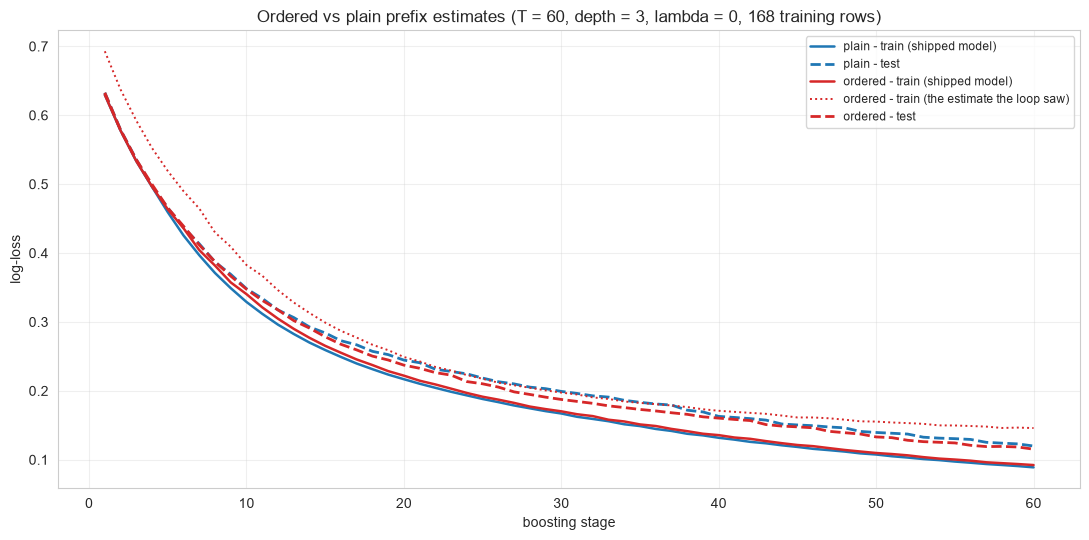

final shipped-model logloss:   plain train 0.0889 | test 0.1198 | gap -0.0310
                               ordered train 0.0922 | test 0.1152 | gap -0.0230
the ordered loop's own (unbiased) train estimate ends at 0.1459, beside its test read 0.1152 - the two tracks the shift was removing

💡 The prediction shift, plotted: the plain loop's train curve runs systematically
   below its test curve (the model grades its own homework), while the ordered
   loop's estimate-the-loop-saw tracks its test curve closely. On a 168-row toy
   the margins are modest - the mechanism, not a leaderboard; the paper's claims
   and the library's auto-switch are sized for the CATALOGUE of small datasets.


In [12]:
# The controlled experiment: one flag, two gradient sources
T_ORD, NU_ORD, DEPTH_ORD = 60, NU_HAND, 3
X_ord_tr, y_ord_tr = X_ob_tr, y_ob_tr

run_plain = ordered_cat_boost(X_ord_tr, y_ord_tr, X_ob_te, y_ob_te,
                              T_ORD, NU_ORD, depth=DEPTH_ORD, ordered=False, seed=0)
run_ordered = ordered_cat_boost(X_ord_tr, y_ord_tr, X_ob_te, y_ob_te,
                                T_ORD, NU_ORD, depth=DEPTH_ORD, ordered=True, seed=0)

fig, ax_ob = plt.subplots(figsize=(11, 5.5))
st_ord = np.arange(1, T_ORD + 1)
ax_ob.plot(st_ord, run_plain["hist"]["train shipped"], lw=1.8, color="#1f77b4",
           label="plain - train (shipped model)")
ax_ob.plot(st_ord, run_plain["hist"]["test"], lw=2.0, color="#1f77b4", ls="--",
           label="plain - test")
ax_ob.plot(st_ord, run_ordered["hist"]["train shipped"], lw=1.8, color="#d62728",
           label="ordered - train (shipped model)")
ax_ob.plot(st_ord, run_ordered["hist"]["train estimated"], lw=1.4, color="#d62728",
           ls=":", label="ordered - train (the estimate the loop saw)")
ax_ob.plot(st_ord, run_ordered["hist"]["test"], lw=2.0, color="#d62728", ls="--",
           label="ordered - test")
ax_ob.set_xlabel("boosting stage")
ax_ob.set_ylabel("log-loss")
ax_ob.set_title(f"Ordered vs plain prefix estimates (T = {T_ORD}, depth = {DEPTH_ORD}, "
                f"lambda = 0, 168 training rows)")
ax_ob.legend(fontsize=8.5)
ax_ob.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plain_gap = run_plain["hist"]["train shipped"][-1] - run_plain["hist"]["test"][-1]
order_gap = run_ordered["hist"]["train shipped"][-1] - run_ordered["hist"]["test"][-1]
print(f"final shipped-model logloss:   plain train {run_plain['hist']['train shipped'][-1]:.4f} "
      f"| test {run_plain['hist']['test'][-1]:.4f} | gap {plain_gap:+.4f}")
print(f"                               ordered train "
      f"{run_ordered['hist']['train shipped'][-1]:.4f} "
      f"| test {run_ordered['hist']['test'][-1]:.4f} | gap {order_gap:+.4f}")
print(f"the ordered loop's own (unbiased) train estimate ends at "
      f"{run_ordered['hist']['train estimated'][-1]:.4f}, beside its test read "
      f"{run_ordered['hist']['test'][-1]:.4f} - the two tracks the shift was removing")
print("\n💡 The prediction shift, plotted: the plain loop's train curve runs systematically")
print("   below its test curve (the model grades its own homework), while the ordered")
print("   loop's estimate-the-loop-saw tracks its test curve closely. On a 168-row toy")
print("   the margins are modest - the mechanism, not a leaderboard; the paper's claims")
print("   and the library's auto-switch are sized for the CATALOGUE of small datasets.")

---

## 6. Implementation with CatBoost

CatBoost 1.2 presents one compiled engine through two doors, like XGBoost (09) and LightGBM (10):

- The **sklearn estimator interface** — `CatBoostClassifier` / `CatBoostRegressor` — plugs into `cross_val_score`, `GridSearchCV`, and the rest of the sklearn ecosystem; the constructor accepts native *and* sklearn names (`learning_rate`/`eta`, `iterations`/`num_boost_round`, `depth`/`max_depth`, `l2_leaf_reg`/`reg_lambda`, `border_count`/`max_bin`, ...)
- The **native container** — `Pool(X, label, cat_features=..., feature_names=...)` — carries the declared categoricals through `fit`, evaluation, and importance machinery directly

Interface notes worth pinning (verified against the pinned version's reference):

- **Verbosity**: CatBoost is chatty — without `verbose=False` the fit prints a progress bar and the resolved learning rate ("learning rate set to ..."); `verbose=0` or `logging_level="Silent"` are the alternatives
- **`cat_features` belongs to the constructor** (names or indices); strings inside a declared column are categories, NaNs among them become the string `"None"`, and an *undeclared* string column is a loud type error
- **Early stopping**: `early_stopping_rounds` (constructor or `fit`) needs an `eval_set`; with `use_best_model=True` only the best trees are kept — `tree_count_`/`best_iteration_`/`best_score_` report the verdict
- **Eval history**: `evals_result_` (attribute) and `get_evals_result()` (method) both exist; keys are `learn` and `validation`
- **Importances**: `feature_importances_` (sklearn-style) and `get_feature_importance(data, type=...)` with types `PredictionValuesChange` (the default), `LossFunctionChange`, `Interaction` (feature-pairs), `ShapValues` (an `(n, n_features + 1)` contributions matrix), `PredictionDiff`
- **Threads**: `thread_count` defaults to −1 = every core; give the estimator `thread_count=1` inside a parallel sklearn sweep (§7), the anti-thrashing arrangement LightGBM's `n_jobs=1` advice gave
- **Stage replay**: `staged_predict` yields predictions over growing tree ranges — the hand loops' replay, provided by the library
- `plot_tree` exists **but needs graphviz** (absent in this environment) — structural reads here use importances and prediction mechanics instead

CatBoost defaults the wrapper resolves (a few, from get_params()):
          iterations = 'n/a'
       learning_rate = 'n/a'
               depth = 'n/a'
         l2_leaf_reg = 'n/a'
        border_count = 'n/a'
         grow_policy = 'n/a'
       boosting_type = 'n/a'
      bootstrap_type = 'n/a'
    one_hot_max_size = 'n/a'
     random_strength = 'n/a'
         eval_metric = 'n/a'
  auto_class_weights = 'n/a'
             verbose = 'n/a'

resolved after fit (get_all_params):
             boosting_type = 'Plain'
            bootstrap_type = 'MVS'
                 subsample = 0.800000011920929
         colsample_bylevel = 'n/a'
    leaf_estimation_method = 'Newton'
  leaf_estimation_iterations = 10
                  nan_mode = 'Min'
          min_data_in_leaf = 1

learning_rate_ (auto-resolved): 0.004810
trees in the ensemble:          1000
test accuracy at the defaults:  100.0%


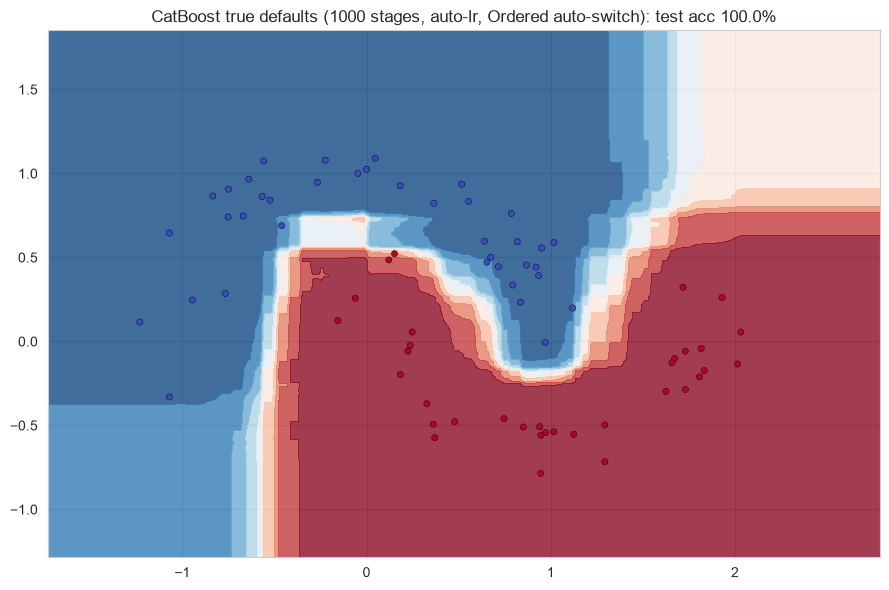


💡 LightGBM's default fit spends 100 stages at lr 0.1 greedily; CatBoost's default
   spends 1000 stages at ~0.03 with an oblivious depth-6 tree and lambda = 3 —
   the same philosophy under a different budget: slow small steps, regularization
   on by default, fewer chances for one tree to go rogue. On 168 rows the Ordered
   auto-switch is the boost this run got for free.


In [13]:
# CatBoost's own defaults, resolved live on the moons fit
Xm6_cb, ym6_cb = make_moons(n_samples=240, noise=0.15, random_state=0)
Xm6_tr_cb, Xm6_te_cb, ym6_tr_cb, ym6_te_cb = train_test_split(Xm6_cb, ym6_cb,
                                                              test_size=0.3, random_state=42)

clf_first_cb = CatBoostClassifier(random_state=0).fit(Xm6_tr_cb, ym6_tr_cb, verbose=False)
defaults_cb = clf_first_cb.get_params()
show_cb = ["iterations", "learning_rate", "depth", "l2_leaf_reg", "border_count",
           "grow_policy", "boosting_type", "bootstrap_type", "one_hot_max_size",
           "random_strength", "eval_metric", "auto_class_weights", "verbose"]
print("CatBoost defaults the wrapper resolves (a few, from get_params()):")
for key_cb in show_cb:
    print(f"  {key_cb:>18s} = {defaults_cb.get(key_cb, 'n/a')!r}")

all_par_cb = clf_first_cb.get_all_params()
print("\nresolved after fit (get_all_params):")
for key_cb in ["boosting_type", "bootstrap_type", "subsample", "colsample_bylevel",
               "leaf_estimation_method", "leaf_estimation_iterations", "nan_mode",
               "min_data_in_leaf"]:
    print(f"  {key_cb:>24s} = {all_par_cb.get(key_cb, 'n/a')!r}")
print(f"\nlearning_rate_ (auto-resolved): {clf_first_cb.learning_rate_:.6f}")
print(f"trees in the ensemble:          {clf_first_cb.tree_count_}")
print(f"test accuracy at the defaults:  {clf_first_cb.score(Xm6_te_cb, ym6_te_cb):.1%}")

pad_cb = 0.5
xx_cb, yy_cb = np.meshgrid(
    np.linspace(Xm6_cb[:, 0].min() - pad_cb, Xm6_cb[:, 0].max() + pad_cb, 220),
    np.linspace(Xm6_cb[:, 1].min() - pad_cb, Xm6_cb[:, 1].max() + pad_cb, 220),
)
grid_cb = np.c_[xx_cb.ravel(), yy_cb.ravel()]
field_cb = clf_first_cb.predict_proba(grid_cb)[:, 1].reshape(xx_cb.shape)

fig, ax_cb = plt.subplots(figsize=(9, 6))
ax_cb.contourf(xx_cb, yy_cb, field_cb, levels=np.linspace(0.0, 1.0, 11), cmap="RdBu_r",
               alpha=0.8)
ax_cb.scatter(Xm6_te_cb[:, 0], Xm6_te_cb[:, 1], c=ym6_te_cb, cmap="coolwarm", s=20,
              edgecolors="k", linewidths=0.3)
ax_cb.set_title("CatBoost true defaults (1000 stages, auto-lr, Ordered auto-switch): "
                f"test acc {clf_first_cb.score(Xm6_te_cb, ym6_te_cb):.1%}")
plt.tight_layout()
plt.show()

print("\n💡 LightGBM's default fit spends 100 stages at lr 0.1 greedily; CatBoost's default")
print("   spends 1000 stages at ~0.03 with an oblivious depth-6 tree and lambda = 3 —")
print("   the same philosophy under a different budget: slow small steps, regularization")
print("   on by default, fewer chances for one tree to go rogue. On 168 rows the Ordered")
print("   auto-switch is the boost this run got for free.")

### Dual Engine: the Family Twin vs CatBoost on the Same Data

Both engines get the identical moons split, 40 stages, $\nu = 0.1$, depth 3. To make the comparison sharp, the parity knobs align CatBoost with the twin: `l2_leaf_reg = 0` (tween λ = 0), `bootstrap_type="No"` (no row sampling in either engine), `random_strength=0` (no gain noise), and two boosting types side by side — `Plain`, the classic loop the twin embodies, and `Ordered`, the chapter's signature (the twin has no prefix machinery to align with).

Expect close but not identical, for the same reasons notebook 10 listed, reshaped:

- **Split universe**: the twin scans raw feature values with least-squares splits; CatBoost prices candidates on the gain formula over ≤ 254 borders — different criterion, different candidate grids
- **Shape**: even at the same `depth = 3`, a free-formed skyline versus a level-symmetric pyramid — the twin's tree may split anywhere its children lead, CatBoost's picks one condition per level
- **Ordered**: the third run changes the gradient table itself — the §5 mechanism, library-grade

                           twin   cb Plain  cb Ordered
test accuracy             95.8%      95.8%      100.0%
mean |p - p_twin|                   0.0334      0.0425
label agreement                      94.4%       95.8%
fit time (s)                          0.03        0.12 (1.23 for the twin)


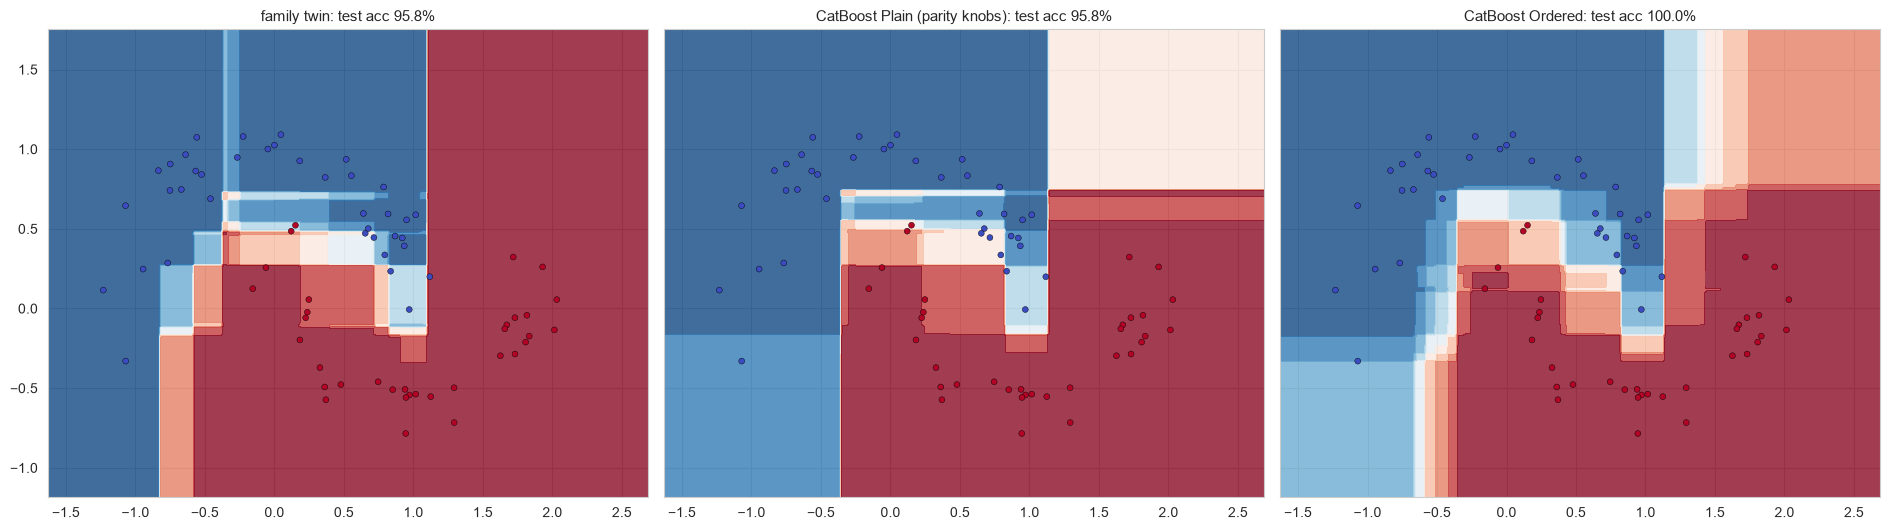


💡 Same skeleton, different split currency and shape law -> the fields agree in
   structure, differ in texture. And the Ordered field is the chapter's point:
   the boundary renders with the row-self-estimates removed from the fitting table.


In [14]:
# The dual-engine check: twin vs CatBoost Plain vs CatBoost Ordered, identical split
PAR_CB = dict(iterations=40, learning_rate=NU_HAND, depth=3, l2_leaf_reg=0.0,
              bootstrap_type="No", random_strength=0.0, verbose=False, random_state=0)

t0 = time.perf_counter()
twin_cb = GradientBoostingClassifierScratch(n_estimators=40, learning_rate=NU_HAND,
                                            max_depth=3).fit(Xm6_tr_cb, ym6_tr_cb)
t_twin_cb = time.perf_counter() - t0

t0 = time.perf_counter()
cb_plain = CatBoostClassifier(boosting_type="Plain", **PAR_CB).fit(Xm6_tr_cb, ym6_tr_cb)
t_plain_cb = time.perf_counter() - t0

t0 = time.perf_counter()
cb_ordered = CatBoostClassifier(boosting_type="Ordered", **PAR_CB).fit(Xm6_tr_cb, ym6_tr_cb)
t_ord_cb = time.perf_counter() - t0

proba_twin_cb = twin_cb.predict_proba(Xm6_te_cb)[:, 1]
proba_plain_cb = cb_plain.predict_proba(Xm6_te_cb)[:, 1]
proba_order_cb = cb_ordered.predict_proba(Xm6_te_cb)[:, 1]

print(f"{'':22s} {'twin':>8s} {'cb Plain':>10s} {'cb Ordered':>11s}")
print(f"{'test accuracy':22s} {twin_cb.score(Xm6_te_cb, ym6_te_cb):>8.1%} "
      f"{cb_plain.score(Xm6_te_cb, ym6_te_cb):>10.1%} "
      f"{cb_ordered.score(Xm6_te_cb, ym6_te_cb):>11.1%}")
print(f"{'mean |p - p_twin|':22s} {'':>8s} "
      f"{np.abs(proba_plain_cb - proba_twin_cb).mean():>10.4f} "
      f"{np.abs(proba_order_cb - proba_twin_cb).mean():>11.4f}")
print(f"{'label agreement':22s} {'':>8s} "
      f"{np.mean((proba_plain_cb >= 0.5) == (proba_twin_cb >= 0.5)) * 100:>9.1f}% "
      f"{np.mean((proba_order_cb >= 0.5) == (proba_twin_cb >= 0.5)) * 100:>10.1f}%")
print(f"{'fit time (s)':22s} {'':>8s} {t_plain_cb:>10.2f} {t_ord_cb:>11.2f} "
      f"({t_twin_cb:.2f} for the twin)")

pad_de_cb = 0.4
xx_de_cb, yy_de_cb = np.meshgrid(
    np.linspace(Xm6_cb[:, 0].min() - pad_de_cb, Xm6_cb[:, 0].max() + pad_de_cb, 250),
    np.linspace(Xm6_cb[:, 1].min() - pad_de_cb, Xm6_cb[:, 1].max() + pad_de_cb, 250),
)
grid_de_cb = np.c_[xx_de_cb.ravel(), yy_de_cb.ravel()]
fig, axes_cb = plt.subplots(1, 3, figsize=(19, 5.4), sharey=True)
for ax_de, (name_de, est_de) in zip(axes_cb, [
        ("family twin", twin_cb),
        ("CatBoost Plain (parity knobs)", cb_plain),
        ("CatBoost Ordered", cb_ordered)]):
    Z_de = est_de.predict_proba(grid_de_cb)[:, 1].reshape(xx_de_cb.shape)
    ax_de.contourf(xx_de_cb, yy_de_cb, Z_de, levels=np.linspace(0.0, 1.0, 11),
                   cmap="RdBu_r", alpha=0.8)
    ax_de.scatter(Xm6_te_cb[:, 0], Xm6_te_cb[:, 1], c=ym6_te_cb, cmap="coolwarm", s=18,
                  edgecolors="k", linewidths=0.3)
    ax_de.set_title(f"{name_de}: test acc {est_de.score(Xm6_te_cb, ym6_te_cb):.1%}",
                    fontsize=11)
plt.tight_layout()
plt.show()

print("\n💡 Same skeleton, different split currency and shape law -> the fields agree in")
print("   structure, differ in texture. And the Ordered field is the chapter's point:")
print("   the boundary renders with the row-self-estimates removed from the fitting table.")

### Regression with CatBoost: `CatBoostRegressor`

The same staged oblivious machinery under the squared-error objective. Off the docs' parameter reference: the RMSE loss keeps constant curvature $h \equiv 1$ — every leaf value is the (λ-smoothed) **mean residual** of its leaf — and by default its leaf phase runs a single `Gradient` (mean-style) step, while the classification losses refine with `Newton` × 10. Here the hand engine of §5 covers that case exactly: with $h \equiv 1$ the one-step Newton value IS the leaf mean.

Depth-to-capacity translation: "stumps" in CatBoost is `depth = 1` — one shared condition per stage tree, the low-variance end of the sweep.

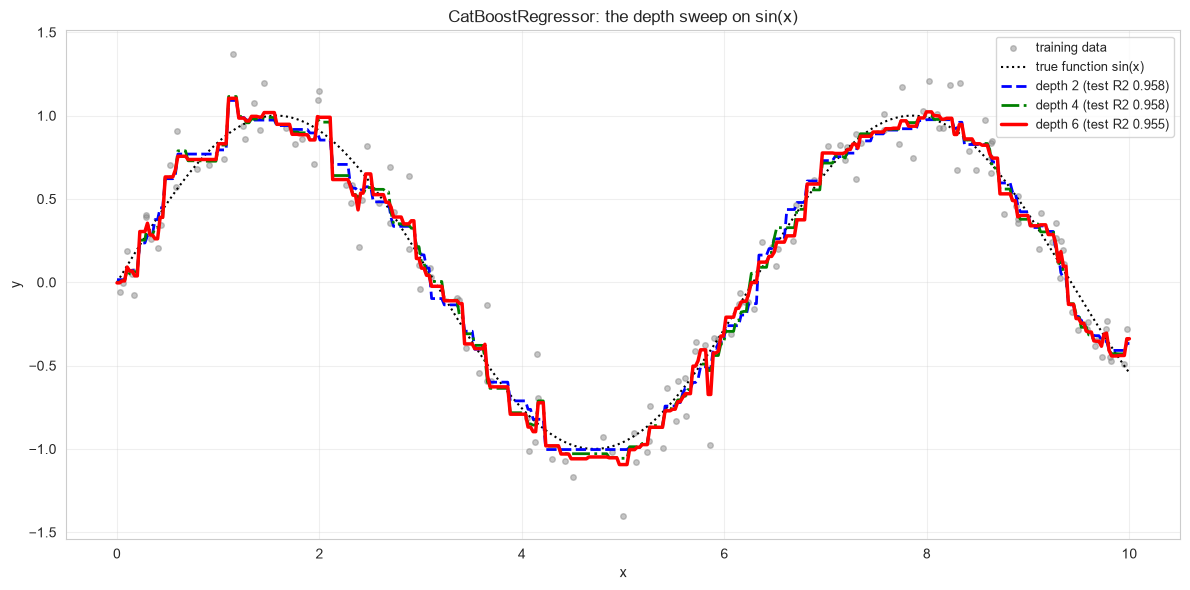

depth=2: train R2 0.9549 | test R2 0.9577 | test RMSE 0.1463
depth=4: train R2 0.9628 | test R2 0.9582 | test RMSE 0.1454
depth=6: train R2 0.9732 | test R2 0.9547 | test RMSE 0.1514

💡 depth = 2 is CatBoost's honest stump: 4 leaves, smooth steps, needs the stages.
   depth = 4 nails the shape; depth = 6 (the default) on 150 training rows starts
   bending into the noise - the same small-data wobble the family showed at
   notebook 10's num_leaves 31, one structural cap deeper than bulls elsewhere.


In [15]:
# The depth sweep inside CatBoostRegressor on sin(x) - same data as notebooks 10/09
rng_r_cb = np.random.default_rng(0)
X_r_cb = np.sort(rng_r_cb.uniform(0.0, 10.0, 200)).reshape(-1, 1)
y_r = np.sin(X_r_cb).ravel() + rng_r_cb.normal(0.0, 0.15, 200)
Xr_cb_tr, Xr_cb_te, yr_cb_tr, yr_cb_te = train_test_split(X_r_cb, y_r, test_size=0.25,
                                                          random_state=42)

reg_cb_d2 = CatBoostRegressor(iterations=200, learning_rate=0.1, depth=2,
                              verbose=False, random_state=0).fit(Xr_cb_tr, yr_cb_tr)
reg_cb_d4 = CatBoostRegressor(iterations=200, learning_rate=0.1, depth=4,
                              verbose=False, random_state=0).fit(Xr_cb_tr, yr_cb_tr)
reg_cb_d6 = CatBoostRegressor(iterations=200, learning_rate=0.1, depth=6,
                              verbose=False, random_state=0).fit(Xr_cb_tr, yr_cb_tr)

grid_r_cb = np.linspace(0.0, 10.0, 400).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(Xr_cb_tr[:, 0], yr_cb_tr, s=16, alpha=0.45, color="gray",
           label="training data")
ax.plot(grid_r_cb, np.sin(grid_r_cb), "k:", lw=1.5, label="true function sin(x)")
ax.plot(grid_r_cb, reg_cb_d2.predict(grid_r_cb), "b--", lw=2,
        label=f"depth 2 (test R2 {r2_score(yr_cb_te, reg_cb_d2.predict(Xr_cb_te)):.3f})")
ax.plot(grid_r_cb, reg_cb_d4.predict(grid_r_cb), "g-.", lw=2,
        label=f"depth 4 (test R2 {r2_score(yr_cb_te, reg_cb_d4.predict(Xr_cb_te)):.3f})")
ax.plot(grid_r_cb, reg_cb_d6.predict(grid_r_cb), "r-", lw=2.5,
        label=f"depth 6 (test R2 {r2_score(yr_cb_te, reg_cb_d6.predict(Xr_cb_te)):.3f})")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("CatBoostRegressor: the depth sweep on sin(x)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for name_reg_cb, reg_cb in [("depth=2", reg_cb_d2), ("depth=4", reg_cb_d4),
                            ("depth=6", reg_cb_d6)]:
    print(f"{name_reg_cb}: train R2 {reg_cb.score(Xr_cb_tr, yr_cb_tr):.4f} | "
          f"test R2 {r2_score(yr_cb_te, reg_cb.predict(Xr_cb_te)):.4f} | "
          f"test RMSE {np.sqrt(mean_squared_error(yr_cb_te, reg_cb.predict(Xr_cb_te))):.4f}")
print("\n💡 depth = 2 is CatBoost's honest stump: 4 leaves, smooth steps, needs the stages.")
print("   depth = 4 nails the shape; depth = 6 (the default) on 150 training rows starts")
print("   bending into the noise - the same small-data wobble the family showed at")
print("   notebook 10's num_leaves 31, one structural cap deeper than bulls elsewhere.")

### Native Categoricals, In the Box

The §3/§5 relationship, now on the library side: CatBoost receives **string columns declared as `cat_features`** and does its ordered statistics, prior smoothing, and cross-feature combinations internally. The demo rebuilds the leak-magnet churn data with real string tiers and brand-new unseen test cities, then fits:

1. the **declared** fit — both `city` and `tier` natively handled
2. the **control** fit — the same model, `city` dropped, so "native handling does not rescue fake signal" is measured rather than asserted

Then the model self-report: `feature_importances_`, and `get_feature_importance(type="Interaction")` for the building blocks CatBoost's trees actually used in pairs.

native fit    (city declared): test acc 65.0%
control fit   (city dropped):  test acc 61.5%
city added +3.5% of test accuracy - a NOISE column cannot earn more than noise


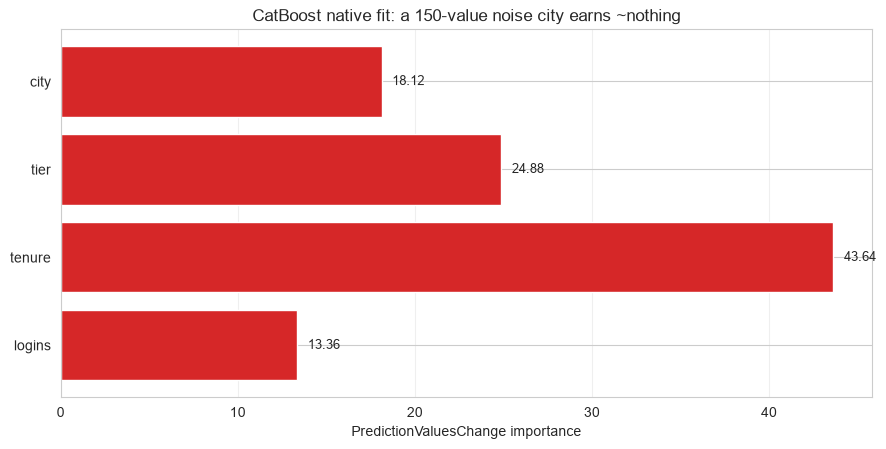

top-5 feature interactions (first_feature, second_feature, strength):
  (   tier,  tenure) ->   24.6787
  (   city,    tier) ->   19.3035
  (   city,  tenure) ->   13.4659
  (   city,  logins) ->    8.3563
  (   tier,  logins) ->    8.3256

💡 Compare with section 3's greedy encoding, where the twin WASTED train accuracy
   on the same noise city. The native machinery keeps city's importance ~0: ordered
   statistics carry no self-target on train rows, so a no-signal column simply has
   no target-conditional structure to sell. Unseen test categories ride in on the
   prior without a single compatibility shim.


In [16]:
# Native categorical handling: StringDtype columns declared, unseen test categories allowed
cities_native_tr = [f"city_{c:03d}" for c in cities_tr]
cities_native_te = [f"city_{c:03d}" for c in cities_te]        # brand-new values, unseen

df_cb_cat = pd.DataFrame({
    "city": cities_native_tr + cities_native_te,
    "tier": list(tiers_cat),
    "tenure": tenure_cat,
    "logins": logins_cat,
})
dfcb_tr, dfcb_te = df_cb_cat.iloc[:n_tr], df_cb_cat.iloc[n_tr:]

cat_native = CatBoostClassifier(iterations=200, learning_rate=0.1, depth=4,
                                cat_features=["city", "tier"],
                                verbose=False, random_state=42).fit(dfcb_tr, churn_cat[:n_tr])
cat_control = CatBoostClassifier(iterations=200, learning_rate=0.1, depth=4,
                                 cat_features=["tier"], verbose=False,
                                 random_state=42).fit(dfcb_tr.drop(columns=["city"]),
                                                      churn_cat[:n_tr])

acc_native_cb = cat_native.score(dfcb_te, churn_cat[n_tr:])
acc_control_cb = cat_control.score(dfcb_te.drop(columns=["city"]), churn_cat[n_tr:])
print(f"native fit    (city declared): test acc {acc_native_cb:.1%}")
print(f"control fit   (city dropped):  test acc {acc_control_cb:.1%}")
print(f"city added {acc_native_cb - acc_control_cb:+.1%} of test accuracy "
      f"- a NOISE column cannot earn more than noise")

imp_cb_cat = pd.Series(cat_native.feature_importances_, index=list(df_cb_cat.columns))
fig, ax_imp_cb = plt.subplots(figsize=(9, 4.6))
ax_imp_cb.barh(imp_cb_cat.index[::-1], imp_cb_cat.values[::-1], color="#d62728")
ax_imp_cb.set_xlabel("PredictionValuesChange importance")
ax_imp_cb.set_title("CatBoost native fit: a 150-value noise city earns ~nothing")
for i_imp_cb, v_imp_cb in enumerate(imp_cb_cat.values[::-1]):
    ax_imp_cb.text(v_imp_cb + 0.6, i_imp_cb, f"{v_imp_cb:.2f}", va="center", fontsize=9)
ax_imp_cb.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

inter_cb = cat_native.get_feature_importance(type="Interaction")   # formula-based, no data
names_cb = list(df_cb_cat.columns)
# the pinned version returns each pair as float-valued (f1, f2, strength) triples - the
# indices come back as floats, so this read casts before it names
inter_matrix_cb = np.asarray(inter_cb, dtype=float).reshape(-1, 3)
print("top-5 feature interactions (first_feature, second_feature, strength):")
for i_cbr, j_cbr, s_cbr in inter_matrix_cb[np.argsort(-inter_matrix_cb[:, 2])[:5]]:
    print(f"  ({names_cb[int(i_cbr)]:>7s}, {names_cb[int(j_cbr)]:>7s}) -> {s_cbr:9.4f}")

print("\n💡 Compare with section 3's greedy encoding, where the twin WASTED train accuracy")
print("   on the same noise city. The native machinery keeps city's importance ~0: ordered")
print("   statistics carry no self-target on train rows, so a no-signal column simply has")
print("   no target-conditional structure to sell. Unseen test categories ride in on the")
print("   prior without a single compatibility shim.")

### Reading the Model Back: SHAP Contributions and Stage Replay

Two library reads that mirror mechanics this notebook hand-built:

- **`get_feature_importance(type="ShapValues", data=...)`** — the per-row contribution matrix of shape `(n, n_features + 1)`: one column per feature plus the expected-value base. Where §5 replayed $F = F_0 + \nu \sum_m h_m(x)$, SHAP decomposes the same $F$ into per-feature contributions
- **`staged_predict`** — the per-stage replay the hand loops did with their own `F` accumulators, provided by the library as a generator over growing tree ranges

In [17]:
# SHAP contributions + staged replay on the native categorical fit
test_pool_cb = Pool(dfcb_te, label=None, cat_features=["city", "tier"])
shap_cat = cat_native.get_feature_importance(test_pool_cb, type="ShapValues")
print(f"ShapValues matrix: {shap_cat.shape}  (last column = the base expected value)")
i_sh = int(np.argmax(np.abs(shap_cat[:, :-1]).sum(axis=1)))
order_sh = np.argsort(-np.abs(shap_cat[i_sh, :-1]))
feat_names_cb = list(dfcb_te.columns)
print(f"most-influenced test row #{i_sh}: dominant feature = {feat_names_cb[order_sh[0]]} "
      f"({shap_cat[i_sh, order_sh[0]]:+.3f} log-odds), base = {shap_cat[i_sh, -1]:+.3f}")
print("per-feature contributions of that row:")
for f_sh in order_sh:
    print(f"  {feat_names_cb[f_sh]:>7s}  {shap_cat[i_sh, f_sh]:+7.3f}")

losses_api = [float(log_loss(churn_cat[n_tr:], p_stage))
              for p_stage in cat_native.staged_predict(dfcb_te,
                                                       prediction_type="Probability")]
stages_api = np.arange(1, len(losses_api) + 1)
print(f"\nstaged replay: {len(losses_api)} per-stage readings over "
      f"{cat_native.tree_count_} trees")
print(f"test log-loss at stages {tuple(stages_api[:3])}: "
      f"{losses_api[0]:.4f}, {losses_api[1]:.4f}, {losses_api[2]:.4f} "
      f"... -> {losses_api[-1]:.4f} final")

print("\n💡 One more door, same engine: SHAP contributions land where the hand replay put")
print("   the log-odds mass, and staged_predict walks the per-stage curve the twin's")
print("   _decision rebuilt cell by cell in section 5 - everything the scratch engines")
print("   taught, the library offers back as a method call.")

ShapValues matrix: (200, 5)  (last column = the base expected value)
most-influenced test row #115: dominant feature = tenure (-2.480 log-odds), base = -0.866
per-feature contributions of that row:
   tenure   -2.480
     city   +0.540
   logins   +0.392
     tier   -0.294

staged replay: 200 per-stage readings over 200 trees
test log-loss at stages (np.int64(1), np.int64(2), np.int64(3)): 0.6791, 0.6666, 0.6579 ... -> 0.6612 final

💡 One more door, same engine: SHAP contributions land where the hand replay put
   the log-odds mass, and staged_predict walks the per-stage curve the twin's
   _decision rebuilt cell by cell in section 5 - everything the scratch engines
   taught, the library offers back as a method call.


---

## 7. Hyperparameter Tuning

The levers that matter, in the order they are usually tuned:

1. **`depth`** (+ `min_data_in_leaf` as the leaf floor) — the structure template: leaf count = $2^{depth}$, hard cap 16 in the docs' parameter reference
2. **`l2_leaf_reg`** — the family λ, shipped at 3 (XGBoost 1, LightGBM 0)
3. **`learning_rate` × `iterations`** (aliases `eta` / `num_boost_round`) — one trade: `learning_rate=None` already auto-resolves a slow-and-steady default
4. **`boosting_type`** — `Ordered` vs `Plain`, the auto-switch that decides whether gradients are read from prefix models at all
5. **`bootstrap_type` / `bagging_temperature` / `subsample` / `colsample_bylevel`** — the stochastic dampers (CPU default: **MVS with `subsample=0.8`** — active out of the box, unlike LightGBM's inert `subsample`)

Four rules govern the sweeps — the same rules as notebooks 08–10, one chapter later:

1. η (and the Bayesian bagging temperature) act multiplicatively — log-scale grids, never linear
2. **η and stage count move together**; tune one, re-check the other
3. Tune with **cross-validation on training data only**; the test set reports once
4. `thread_count` defaults to every core — inside a parallel sklearn sweep (`GridSearchCV(n_jobs=-1)`), give the estimator `thread_count=1`

The tuning data below is a noisier moons set (480 rows, noise 0.25) — the same recipe as notebooks 08/09/10, so the four chapters' hyperparameter stories compare stage for stage.

In [18]:
# The tuning split used throughout section 7 (identical to notebook 10's section 7 split)
Xt7_cb, yt7_cb = make_moons(n_samples=480, noise=0.25, random_state=3)
Xt7_tr, Xt7_te, yt7_tr, yt7_te = train_test_split(Xt7_cb, yt7_cb, test_size=0.3,
                                                  stratify=yt7_cb, random_state=42)
print(f"tuning data: {Xt7_tr.shape[0]} train rows / {Xt7_te.shape[0]} test rows, noise 0.25")

tuning data: 336 train rows / 144 test rows, noise 0.25


 depth  leaves  train acc  test acc
     2       4     0.9762    0.8889
     4      16     1.0000    0.8958
     6      64     1.0000    0.8819
     8     256     1.0000    0.8958
    10    1024     1.0000    0.8889


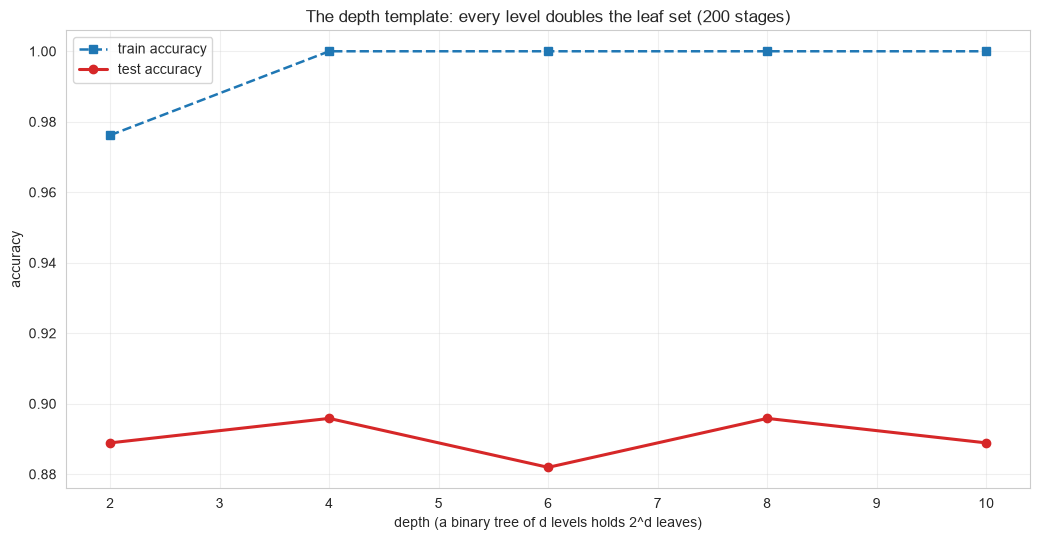


💡 Read against notebook 10's num_leaves sweep: the same train-climb/test-wobble
   curve, step-quantized. Doubling depth doubles the per-stage parameter budget
   - and CatBoost's l2_leaf_reg = 3 plus random_strength slow that climb just a
   little more than LightGBM's zero-default regularizers did.


In [19]:
# The depth sweep: 200 stages at nu = 0.1; the auto-switch runs Ordered <= 50k rows
depth_sweep_cb = [2, 4, 6, 8, 10]
rows_depth_cb = []
for d_cb in depth_sweep_cb:
    m_cb = CatBoostClassifier(iterations=200, learning_rate=0.1, depth=d_cb,
                              verbose=False, random_state=0).fit(Xt7_tr, yt7_tr)
    rows_depth_cb.append({"depth": d_cb,
                          "leaves": 2 ** d_cb,
                          "train acc": m_cb.score(Xt7_tr, yt7_tr),
                          "test acc": m_cb.score(Xt7_te, yt7_te)})

df_depth_cb = pd.DataFrame(rows_depth_cb)
print(df_depth_cb.round(4).to_string(index=False))

fig, ax_depth = plt.subplots(figsize=(10.5, 5.5))
ax_depth.plot(df_depth_cb["depth"], df_depth_cb["train acc"], "s--", color="#1f77b4",
              lw=1.8, label="train accuracy")
ax_depth.plot(df_depth_cb["depth"], df_depth_cb["test acc"], "o-", color="#d62728",
              lw=2.2, label="test accuracy")
ax_depth.set_xlabel("depth (a binary tree of d levels holds 2^d leaves)")
ax_depth.set_ylabel("accuracy")
ax_depth.set_title("The depth template: every level doubles the leaf set (200 stages)")
ax_depth.legend()
ax_depth.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n💡 Read against notebook 10's num_leaves sweep: the same train-climb/test-wobble")
print("   curve, step-quantized. Doubling depth doubles the per-stage parameter budget")
print("   - and CatBoost's l2_leaf_reg = 3 plus random_strength slow that climb just a")
print("   little more than LightGBM's zero-default regularizers did.")

### The Leaf Regularizer: `l2_leaf_reg`

CatBoost's λ is the *one* leaf regularizer (the family's L1 members — XGBoost's and LightGBM's `reg_alpha` — have no CatBoost counterpart) — the L2 term inside $w^* = -G/(H+\lambda)$, shipped at **3**. The sibling chapters' contrast: XGBoost ships λ = 1, LightGBM ships λ = 0 and asks you to add regularizers deliberately. Same algebra, three default philosophies.

 l2_leaf_reg  cv acc
         0.0  0.9286
         0.1  0.9226
         1.0  0.9256
         3.0  0.9315
        30.0  0.9137
       300.0  0.9107


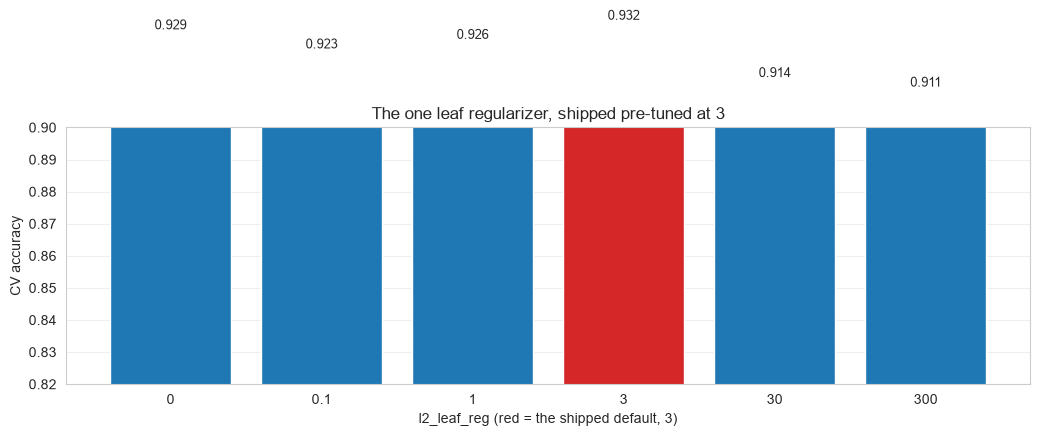

best: l2_leaf_reg = 3 (CV acc 0.9315)

💡 Raising the lambda smooths the leaf values the structure phase just chose -
   the tired-leaf pattern from notebooks 08/09, with the smoothed step already a
   default. Heavy lambdas underfit at 60 stages; the shipped 3 sits near the
   small-data optimum, which is exactly what a default is for.


In [20]:
# l2_leaf_reg sweep under 3-fold stratified CV (60 stages, depth 6)
lam_grid_cb = [0.0, 0.1, 1.0, 3.0, 30.0, 300.0]
cv_lam_cb = StratifiedKFold(3, shuffle=True, random_state=42)
rows_lam_cb = []
for lam_cb in lam_grid_cb:
    m_lam_cb = CatBoostClassifier(iterations=60, learning_rate=0.1, depth=6,
                                  l2_leaf_reg=lam_cb, thread_count=1, verbose=False,
                                  random_state=0)
    rows_lam_cb.append({"l2_leaf_reg": lam_cb,
                        "cv acc": cross_val_score(m_lam_cb, Xt7_tr, yt7_tr, cv=cv_lam_cb,
                                                  scoring="accuracy", n_jobs=-1).mean()})

df_lam_cb = pd.DataFrame(rows_lam_cb)
print(df_lam_cb.round(4).to_string(index=False))

fig, ax_lam = plt.subplots(figsize=(10.5, 5))
colors_lam = ["#d62728" if v_cb == 3.0 else "#1f77b4" for v_cb in df_lam_cb["l2_leaf_reg"]]
ax_lam.bar([f"{v_cb:g}" for v_cb in df_lam_cb["l2_leaf_reg"]], df_lam_cb["cv acc"],
           color=colors_lam)
for i_lam, v_lam in enumerate(df_lam_cb["cv acc"]):
    ax_lam.text(i_lam, v_lam + 0.002, f"{v_lam:.3f}", ha="center", fontsize=9)
best_lam = df_lam_cb.loc[df_lam_cb["cv acc"].idxmax(), "l2_leaf_reg"]
ax_lam.set_ylim(0.82, 0.90)
ax_lam.set_xlabel("l2_leaf_reg (red = the shipped default, 3)")
ax_lam.set_ylabel("CV accuracy")
ax_lam.set_title("The one leaf regularizer, shipped pre-tuned at 3")
ax_lam.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"best: l2_leaf_reg = {best_lam:g} (CV acc "
      f"{df_lam_cb['cv acc'].max():.4f})")
print("\n💡 Raising the lambda smooths the leaf values the structure phase just chose -")
print("   the tired-leaf pattern from notebooks 08/09, with the smoothed step already a")
print("   default. Heavy lambdas underfit at 60 stages; the shipped 3 sits near the")
print("   small-data optimum, which is exactly what a default is for.")

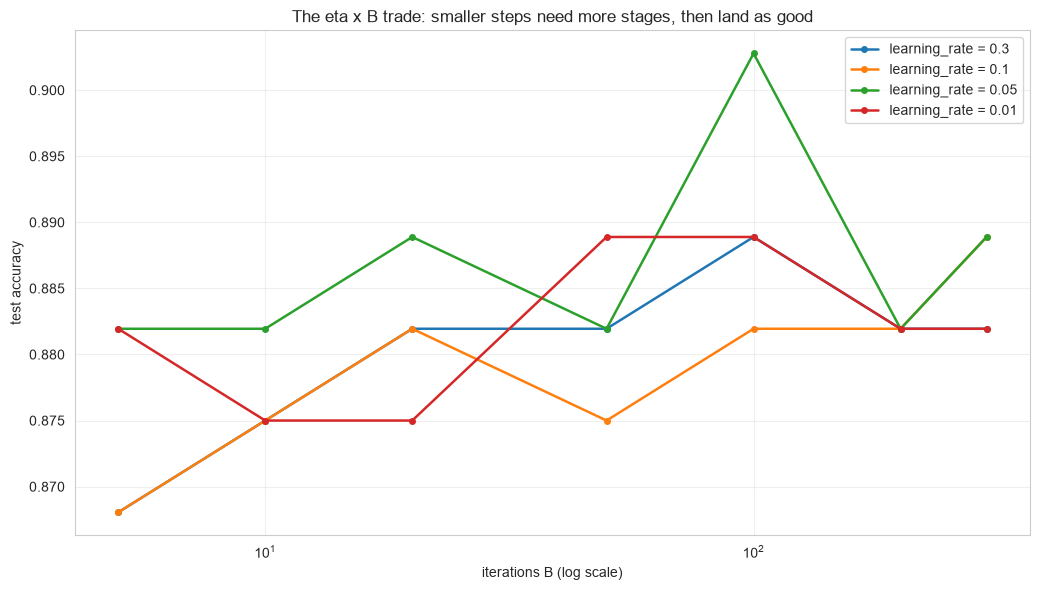

   eta | best B | best test acc
  0.30 |    100 |         88.9%
  0.10 |    300 |         88.9%
  0.05 |    100 |         90.3%
  0.01 |     50 |         88.9%

💡 Notebook 08/09/10's trade, unchanged by the shape law. What changed is the
   SHIPPING default: an auto-resolved learning rate around 0.03 with a 1000-stage
   budget sits in the slow-steps lane this grid's eta = 0.05/300 corner begins -
   the factory configuration already lives where this family's sweeps land.


In [21]:
# The eta x iterations trade: refits across a stage grid (same grid as notebooks 08-10)
B_cb_sweep = [5, 10, 20, 50, 100, 200, 300]
eta_cb_sweep = [0.3, 0.1, 0.05, 0.01]
acc_by_eta_cb = {}
for eta_cb in eta_cb_sweep:
    test_curve_cb = []
    for B_cb in B_cb_sweep:
        m_cb = CatBoostClassifier(iterations=B_cb, learning_rate=eta_cb, depth=6,
                                  verbose=False, random_state=0).fit(Xt7_tr, yt7_tr)
        test_curve_cb.append(accuracy_score(yt7_te, m_cb.predict(Xt7_te)))
    acc_by_eta_cb[eta_cb] = np.array(test_curve_cb)

fig, ax_eta = plt.subplots(figsize=(10.5, 6))
for eta_cb in eta_cb_sweep:
    ax_eta.plot(B_cb_sweep, acc_by_eta_cb[eta_cb], marker="o", ms=4, lw=1.8,
                label=f"learning_rate = {eta_cb}")
ax_eta.set_xscale("log")
ax_eta.set_xlabel("iterations B (log scale)")
ax_eta.set_ylabel("test accuracy")
ax_eta.set_title("The eta x B trade: smaller steps need more stages, then land as good")
ax_eta.legend()
ax_eta.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'eta':>6s} | {'best B':>6s} | {'best test acc':>13s}")
for eta_cb in eta_cb_sweep:
    best_i_cb = int(acc_by_eta_cb[eta_cb].argmax())
    print(f"{eta_cb:>6.2f} | {B_cb_sweep[best_i_cb]:>6d} | "
          f"{acc_by_eta_cb[eta_cb][best_i_cb]:>13.1%}")
print("\n💡 Notebook 08/09/10's trade, unchanged by the shape law. What changed is the")
print("   SHIPPING default: an auto-resolved learning rate around 0.03 with a 1000-stage")
print("   budget sits in the slow-steps lane this grid's eta = 0.05/300 corner begins -")
print("   the factory configuration already lives where this family's sweeps land.")

### `boosting_type`: Ordered vs Plain, the Auto-Switch

The docs' rule is exact and worth internalizing:

| condition (CPU) | shipped `boosting_type` |
|---|---|
| ≤ 50 thousand objects, classification/regression | **Ordered** |
| > 50 thousand objects (or `MultiClass` losses) | Plain (still with ordered categorical statistics) |

`Ordered` costs real time — ≈$\log_2 n$ auxiliary models updated per stage (§5's loop is the honest picture). `Plain` is the classic loop with the ordered *statistics* kept. The comparison below measures both the accuracy and the clock on the same fit.

In [22]:
# Plain vs Ordered on the same fit - accuracy AND the clock
t0 = time.perf_counter()
cb_plain_tune = CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6,
                                   boosting_type="Plain", verbose=False,
                                   random_state=0).fit(Xt7_tr, yt7_tr)
t_plain_cb = time.perf_counter() - t0

t0 = time.perf_counter()
cb_order_tune = CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6,
                                   boosting_type="Ordered", verbose=False,
                                   random_state=0).fit(Xt7_tr, yt7_tr)
t_order_cb = time.perf_counter() - t0

print(f"{'':32s} {'Plain':>10s} {'Ordered':>10s}")
print(f"{'test accuracy':32s} {cb_plain_tune.score(Xt7_te, yt7_te):>10.1%} "
      f"{cb_order_tune.score(Xt7_te, yt7_te):>10.1%}")
print(f"{'train accuracy':32s} {cb_plain_tune.score(Xt7_tr, yt7_tr):>10.1%} "
      f"{cb_order_tune.score(Xt7_tr, yt7_tr):>10.1%}")
print(f"{'fit time (s)':32s} {t_plain_cb:>10.2f} {t_order_cb:>10.2f}")
print("\n💡 Ordered buys its keep on small, noisy data - the auto-switch picks it exactly")
print("   where classic self-fitted gradients overfit fastest - and pays its time to the")
print("   prefix-model bookkeeping that §5's hand loop made visible. On a big table the")
print("   same split rule flips to Plain: speed first, ordered statistics still keeping")
print("   the categorical encodings honest.")

                                      Plain    Ordered
test accuracy                         88.2%      88.9%
train accuracy                       100.0%     100.0%
fit time (s)                           0.37       1.51

💡 Ordered buys its keep on small, noisy data - the auto-switch picks it exactly
   where classic self-fitted gradients overfit fastest - and pays its time to the
   prefix-model bookkeeping that §5's hand loop made visible. On a big table the
   same split rule flips to Plain: speed first, ordered statistics still keeping
   the categorical encodings honest.


### Early Stopping: A Stage Budget, Not a Target

Early stopping rides in through `fit` (or the constructor) as `early_stopping_rounds`, and it **requires an `eval_set`** — without a validation set there is nothing to watch. With `use_best_model=True` only the best trees are kept afterwards (`tree_count_` reports the kept count; `best_iteration_`/`best_score_` report the verdict). The eval history lands in `evals_result_` (and its `get_evals_result()` twin), keyed `"learn"` and `"validation"`.

The docs' recommendation carries over unchanged: cross-validate to choose hyperparameters, then retrain the final model **on the full training data with early stopping** — ES inside CV changes the model's stage count per fold and muddies comparisons.

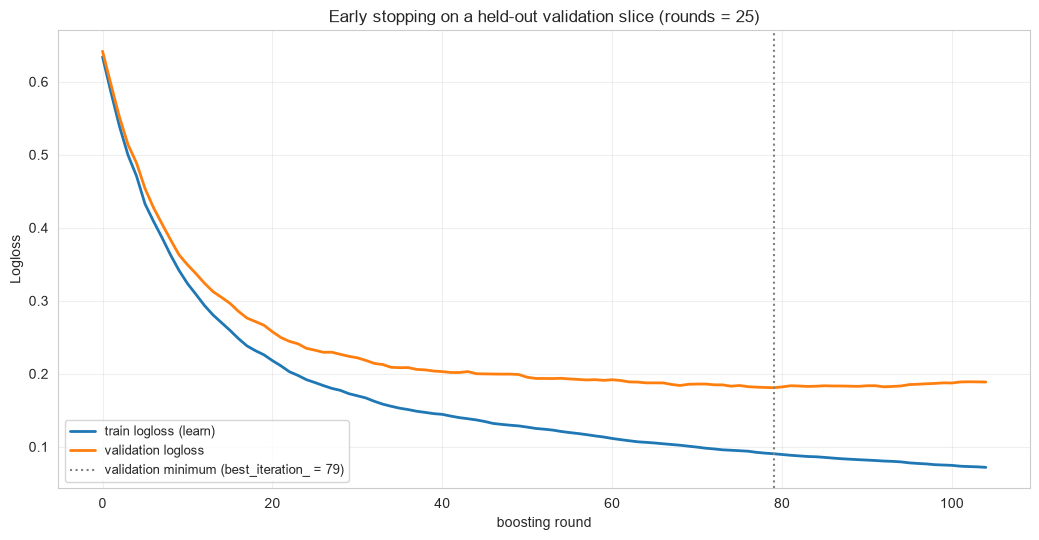

requested 600; early stopping stopped and use_best_model kept tree_count_ = 80 of them (best_iteration_ = 79)
best_score_ = {'learn': {'Logloss': 0.07179431772943753}, 'validation': {'Logloss': 0.18083063323656678}}
test accuracy (kept best trees only): 88.9%

💡 The staged-loss curve tells the same story as notebooks 08/09/10: train keeps
   sinking, validation flattens then turns - and the kept-tree count makes the
   verdict physical. n_iterations is a budget, never a target.


In [23]:
# Validation carved out of the TRAINING portion - the test set stays sealed
Xv7_cb_tr, Xv7_cb_val, yv7_cb_tr, yv7_cb_val = train_test_split(
    Xt7_tr, yt7_tr, test_size=0.2, stratify=yt7_tr, random_state=42)

clf_es_cb = CatBoostClassifier(iterations=600, learning_rate=0.05, depth=6,
                               verbose=False, random_state=0)
clf_es_cb.fit(Xv7_cb_tr, yv7_cb_tr,
              eval_set=(Xv7_cb_val, yv7_cb_val),
              early_stopping_rounds=25, use_best_model=True)

history_cb = clf_es_cb.evals_result_
learn_key, valid_key = list(history_cb.keys())[:2]
metric_key = [k for k in history_cb[valid_key] if "Logloss" in k][0]

fig, ax_es = plt.subplots(figsize=(10.5, 5.5))
ax_es.plot(history_cb[learn_key][metric_key], lw=2, label="train logloss (learn)")
ax_es.plot(history_cb[valid_key][metric_key], lw=2, label="validation logloss")
ax_es.axvline(clf_es_cb.best_iteration_, color="gray", ls=":", lw=1.5,
              label=f"validation minimum (best_iteration_ = {clf_es_cb.best_iteration_})")
ax_es.set_xlabel("boosting round")
ax_es.set_ylabel("Logloss")
ax_es.set_title("Early stopping on a held-out validation slice (rounds = 25)")
ax_es.legend(fontsize=9)
ax_es.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"requested 600; early stopping stopped and use_best_model kept "
      f"tree_count_ = {clf_es_cb.tree_count_} of them (best_iteration_ = "
      f"{clf_es_cb.best_iteration_})")
print(f"best_score_ = {clf_es_cb.best_score_}")
print(f"test accuracy (kept best trees only): {clf_es_cb.score(Xt7_te, yt7_te):.1%}")
print("\n💡 The staged-loss curve tells the same story as notebooks 08/09/10: train keeps")
print("   sinking, validation flattens then turns - and the kept-tree count makes the")
print("   verdict physical. n_iterations is a budget, never a target.")

---

## 8. Complete Hyperparameter Reference

### CatBoost Parameters (catboost 1.2.10)

Both spellings pass through one constructor — the native parameter registry and its sklearn-facing aliases (the merged tables from the pinned version's classifier reference). Defaults below are the pinned version's own, read off `get_params()` and the parameter reference; `None` means resolved automatically at fit.

#### `iterations` (int, default=1000; aliases: `n_estimators`, `num_boost_round`, `num_trees`) **[THE BUDGET]**
- **Description**: the stage count — as many oblivious trees (plain) or shared-structure rounds (ordered)
- **Effect**: the shipped 1000-stage budget expects the auto-resolved slow learning rate; with early stopping it is a ceiling, not a target (§7)
- **Example**: `CatBoostClassifier(n_estimators=1000, ...)` + `early_stopping_rounds=25` on a carved validation slice

#### `learning_rate` (float, default=None → auto; alias: `eta`) **[THE OTHER HALF]**
- **Description**: the shrinkage $\nu$ on every stage's contribution; resolved from the iteration budget and dataset size when left as `None` (a small-data, 1000-stage fit lands near 0.03 — the fit log announces it unless `verbose=False`)
- **Example**: `learning_rate=0.05` + `iterations=1000` + early stopping; `learning_rate=0.1` for short sweeps

#### `depth` (int, default=6, hard max 16; aliases: `max_depth`) **[THE STRUCTURE KNOB]**
- **Description**: the number of shared conditions — an oblivious tree of depth $d$ has $2^d$ leaves and *exactly* $d$ split conditions (§2's economy table)
- **Effect**: the level-symmetric analog of XGBoost's `max_depth`; on small data 6 levels is generous — the depth sweep in §7 quantifies when the extra levels bend into noise
- **Example**: `depth=4` for a few thousand rows

#### `l2_leaf_reg` (float, default=3; alias: `reg_lambda`) **[THE LAMBDA]**
- **Description**: the L2 penalty inside $w^* = -G/(H+\lambda)$ — the same algebra as notebooks 08–10, shipped at **3**
- **Effect**: raises the floor under leaf values; the built-in damping the other two libraries leave to you (§7's sweep)
- **Example**: `l2_leaf_reg=10` when the train-test gap yawns

#### `border_count` (int, default=254 on CPU, 128 on GPU; alias: `max_bin`) + `feature_border_type` (default `GreedyLogSum`)
- **Description**: the quantization budget — splits are searched over this many borders per float feature (the histogram family's bins, one chapter later)
- **Note**: `get_borders()` reads the actual borders back per feature
- **Example**: `border_count=64` for throughput on wide tables

#### `boosting_type` (str, default=None → auto; `Plain`, `Ordered`)
- **Description**: whether gradients are read from prefix models. **Auto = Ordered when ≤ 50k objects on CPU (classification/regression), Plain otherwise or for `MultiClass`** — the small-data switch this notebook's whole chapter lives inside
- **Effect**: Ordered = the anti-prediction-shift machinery, ~$\log_2 n$ auxiliary models per stage; Plain = the classic loop with the ordered statistics kept
- **Example**: `boosting_type="Ordered"` deliberately on a 5k-row noisy set; `"Plain"` on a million-row table

#### `bootstrap_type` (str, default=None → auto) + **`bagging_temperature`** (default=1) + **`subsample`** (active per type)
- **Description**: the row-sampler. Auto on CPU: **MVS** (Minimum Variance Sampling) with **`subsample=0.8`**; Bayesian on GPU and for `MultiClass` (weights drawn as $w_i e^{-\tau \xi_i}$ with $\tau$ = `bagging_temperature`); Bernoulli = plain binomial row dropping; `Poisson` and `No` round out the list
- **Effect**: unlike LightGBM's inert-by-default `subsample`, the CPU default is already sampling 20% of rows per stage — the stochastic damper is ON by design
- **Example**: `bootstrap_type="No"` when a run must be exactly reproducible down to the bit; `bootstrap_type="Bayesian", bagging_temperature=2` for heavier bagging

#### `colsample_bylevel` (float, default=1 on CPU; alias: `rsm`)
- **Description**: fraction of features sampled per level — the column damper, applied per oblivious level here
- **Example**: `colsample_bylevel=0.7` on wide feature spaces

#### `random_strength` (float, default=1)
- **Description**: the L2-scaled random noise added to candidate scores during the split search — a *split-level* regularizer the twin family has no direct knob for
- **Effect**: keeps ties from being decided by float noise; heavier values make structure choices more stochastic
- **Example**: `random_strength=0` inside exact parity checks (§6's dual-engine cell did)

#### `grow_policy` (str, default=`SymmetricTree`; `Depthwise`, `Lossguide`)
- **Description**: the tree shape law. `SymmetricTree` = the oblivious design of §2; `Depthwise` = XGBoost-style level-wise; `Lossguide` = LightGBM-style best-first leaf budget (then `num_leaves`/`max_leaves`, and `min_data_in_leaf`, become the honest knobs)
- **Note**: the symmetric shape is not a constraint — it is a *choice*, and the default one
- **Example**: `grow_policy="Lossguide", num_leaves=31` when a LightGBM config must transplant

#### `min_data_in_leaf` (int, default=1; aliases: `min_child_samples`)
- **Description**: the row-count floor under a leaf (active for `Depthwise`/`Lossguide`; the oblivious law handles its own floors through λ and the level loop)
- **Example**: `min_data_in_leaf=5` on tiny data

#### `one_hot_max_size` (int, default=2 on CPU classification/regression)
- **Description**: categorical features with at most this many values skip the CTR machinery and go one-hot
- **Effect**: low-cardinality tiers become `k` binary columns (one-vs-other splits); everything richer rides ordered statistics
- **Example**: `one_hot_max_size=0` to force CTR treatment even for binary tiers

#### `cat_features` (list of names or indices)
- **Description**: the declaration itself — string columns in a declared list travel the ordered-TS machinery, including cross-feature combinations (below); undeclared strings are a loud error, and NaNs inside declared columns become the string `"None"`
- **Example**: `CatBoostClassifier(cat_features=["city", "tier"])`

#### `simple_ctr` / `combinations_ctr` / `max_ctr_complexity` (default 4) / `ctr_leaf_count_limit`
- **Description**: the CTR engine's tuning surface — per-permutation statistic variants (borders/buckets/counters, prior configurations), which category *combinations* (up to `max_ctr_complexity` features fused) get statistics built over them, and how many CTR leaves may survive
- **Effect**: leave the defaults first; touch them when a specific categorical column must be treated one way only (`per_feature_ctr` exists for exactly that)

#### `nan_mode` (str, default=`Min` on CPU)
- **Description**: the float-NaN route: `Min` sends missing values past the feature's lower border (a learned split can still corner them); `Max` the symmetrical misuse; `Forbidden` refuses
- **Note**: *categorical* NaNs are a different story — they become the string `"None"` (a category), not a NaN

#### `has_time` (bool, default=False)
- **Description**: swap the random permutations for the input row order — for genuinely temporal streams where "earlier in file" *is* the artificial time
- **Example**: `has_time=True` on data whose row order is the event order

#### `auto_class_weights` (str, default=None; `Balanced`, `SqrtBalanced`) + `scale_pos_weight`
- **Description**: the imbalance lever at the loss: class weights derived inversely from class frequencies (or their square root), or the binary `scale_pos_weight` directly
- **Example**: `auto_class_weights="Balanced"` when accuracy hides a minority the recall metric misses

#### `loss_function` (default auto per estimator class; `Logloss`, `CrossEntropy`, `MultiClass`; `RMSE`, `MAE`, `Quantile`+`alpha`, `Huber`+`delta`, `Poisson`, ...) + `eval_metric`
- **Description**: the loss via the wrapper's class inference, or named explicitly; `eval_metric` (defaults to the loss) drives the `evals_result_` history and early stopping, `custom_metric` adds reporting-only metrics
- **Example**: `CatBoostRegressor(loss_function="Quantile", eval_metric="MAE")`

#### `early_stopping_rounds` + `use_best_model` + `od_type` / `od_pval` / `od_wait`
- **Description**: the overfitting-detection family — classic patience (`early_stopping_rounds` or the `Iter`-based `od_wait`), a p-value trigger (`od_pval`), and whether the stored model keeps only the best trees
- **Example**: `fit(..., eval_set=..., early_stopping_rounds=25, use_best_model=True)`

#### `verbose` (int/bool; sklearn-compatible) / `logging_level` (default=`Verbose`) / `metric_period`
- **Description**: the console chatter control. Unsilenced fits print progress *and* the resolved learning rate; `verbose=False` or `logging_level="Silent"` silence them in sweeps
- **Example**: `verbose=False` everywhere in this notebook

#### `thread_count` (int, default=−1) + `random_seed` (alias `random_state`)
- **Description**: −1 = every core (§7's rule: `thread_count=1` inside parallel sklearn sweeps); the seed feeds the permutation draws, bootstraps, and split noise
- **Example**: `random_state=42` for reproducible notebooks

### Fitted Attributes Worth Knowing

- `classes_` — the wrapper's sorted-unique class labels; `feature_names_` — the declared feature names
- `learning_rate_` — the *resolved* learning rate (post-auto-resolution; the none→number story in §6 read it directly)
- `tree_count_` — the kept tree count (final unless early stopping trimmed it); `best_iteration_` / `best_score_` — the ES verdict and per-metric best
- `evals_result_` / `get_evals_result()` — the per-round metric history, an attribute AND a method (XGBoost kept only the method; LightGBM only the property)
- `feature_importances_` — the normalized default importance (`PredictionValuesChange`); richer reads through `get_feature_importance(data, type=...)` (`ShapValues`, `Interaction`, ...)
- `get_all_params()` / `get_borders()` / `save_model(...)` / `load_model(...)` — the introspection set: resolved params, the per-feature border lists, and portable `.cbm` artifacts

### What the Family Twin Covers

| CatBoost parameter | Scratch twin (`GradientBoostingClassifierScratch`) | Notes |
|---|---|---|
| `iterations`/`n_estimators`, `learning_rate` | ✅ | identical meaning; shrinkage once per stage |
| $F_0$ / `boost_from_average` | ✅ | same base-rate constant (`_f0_logit`) |
| Newton leaf values | ✅ at λ=0, one round | `_newton_leaf_values`; λ and the iterative leaf phase hand-built in §5 |
| `l2_leaf_reg` | ❌ (hand-built in §5's loops) | the twin ships no λ |
| oblivious structure | ❌ (hand-built §5) | the twin's trees are free-formed |
| `boosting_type=Ordered` | ❌ (hand-built §5, power-of-two relaxation) | the twin's gradients always come from the full self-model |
| `cat_features`, ordered TS | ❌ (hand-built encoder §5) | the twin is numeric-only |
| `border_count` bins, NaN routing, CTR combinations | ❌ | the compiled engine's contributions |
| MVS/Bayesian sampling, `random_strength` | ❌ | no stochastic stages; `random_state` accepted, unused |
| eval history, early stopping, `shap` reads | ❌ | no per-round logloss tracked to stop on |

### Parameter Combination Recipes

#### Baseline for small-to-medium data (start here):
```python
CatBoostClassifier(depth=4, learning_rate=0.1, iterations=200,
                   verbose=False, random_state=42)
```

#### The stage-budget shape (production default):
```python
CatBoostClassifier(depth=6, learning_rate=0.05, iterations=1000,
                   verbose=False, random_state=42)
# fit(..., eval_set=[(X_val, y_val)], early_stopping_rounds=25, use_best_model=True)
```

#### Categorical-heavy (the engine's showcase):
```python
CatBoostClassifier(cat_features=["city", "tier"], one_hot_max_size=2)
# ordered statistics + combinations run automatically inside
```

#### Large data (flip the auto-switch off):
```python
CatBoostClassifier(boosting_type="Plain", thread_count=-1, border_count=254)
```

#### Imbalanced classes:
```python
CatBoostClassifier(auto_class_weights="Balanced")
```

#### Regression variants:
```python
CatBoostRegressor(loss_function="MAE")                    # outlier-robust
CatBoostRegressor(loss_function="Quantile", alpha=0.9)    # 90th-percentile fit
CatBoostRegressor(loss_function="Poisson")                # counts
```

#### Exactly reproducible runs:
```python
CatBoostClassifier(random_seed=42, bootstrap_type="No", random_strength=0)
```

---

## 9. Practical Tips & Common Pitfalls

### ✅ Best Practices

#### 1. **Declare Categoricals in the Constructor — Then Leave Them Alone**
`cat_features=["city", "tier"]` is the whole contract; the ordered statistics, priors, and combinations are the engine's home turf (§6). Do keep human judgment on *column design*: aggregate absurdly rare tiers before handing them over — no statistic can manufacture evidence.

#### 2. **Silence the Engine in Batch Work**
`verbose=False` in every constructor that might fit more than once; otherwise the progress bars and resolved-learning-rate lines flood the notebook. The training also writes a `catboost_info/` log folder next to the working directory — `allow_writing_files=False` if the repo must stay clean.

#### 3. **Let Early Stopping Hold the Stopwatch**
```python
clf = CatBoostClassifier(depth=6, learning_rate=0.05, iterations=1000, verbose=False)
clf.fit(X_tr, y_tr, eval_set=(X_val, y_val),
        early_stopping_rounds=25, use_best_model=True)
```
Cross-validate to choose knobs, then ES-retrain on the full training data (§7). The verdict is readable from `best_iteration_` and the kept `tree_count_`.

#### 4. **Budget `depth`, Not Leaves**
The shape template doubles leaves per level: `depth=4` is 16 leaves, `depth=6` is 64. On small data the honest move is *down*: depth 3–4, lean on `l2_leaf_reg` — not up.

#### 5. **Trust the Pre-Tuned Regularizers First**
`l2_leaf_reg=3` and `random_strength=1` are already doing quiet work; raise `l2_leaf_reg` when the train-test gap yawns before touching anything exotic.

#### 6. **Give `thread_count` Where the Parallelism Lives**
Inside `GridSearchCV(n_jobs=-1)`, the *outer* sweep should own the cores: the estimator gets `thread_count=1`.

#### 7. **Read Importances, Then Verify Removals**
`feature_importances_` (PredictionValuesChange) and SHAP contributions agree conceptually but not numerically; before dropping a feature, verify with `permutation_importance` as in notebooks 04/08/09.

#### 8. **Match `eval_metric` to the Decision**
Logloss drives early stopping by default; a decision on probabilities wants the reliability check (Brier), a decision on ranking wants the ranking metric — pick the metric *before* the sweep.

### ❌ Common Mistakes

#### 1. **Undeclared String Columns**
```python
# BAD:  CatBoostClassifier().fit(df_with_tier_strings, y)     # loud type error
# GOOD: CatBoostClassifier(cat_features=["tier"]).fit(df_with_tier_strings, y)
```
Undeclared strings fail loudly at fit; *silently numeric* folds are what mislabeled dtypes do — check what the column actually arrived as before trusting a fit.

#### 2. **Forgetting the eval_set under Early Stopping**
```python
# BAD:  fit(..., early_stopping_rounds=25)          # nothing to watch
# GOOD: fit(..., eval_set=(X_val, y_val), early_stopping_rounds=25, use_best_model=True)
```

#### 3. **Ordered on Big Data**
```python
# BAD:  CatBoostClassifier(boosting_type="Ordered").fit(X_1M, y)    # the slow lane
# GOOD: CatBoostClassifier(boosting_type="Plain").fit(X_1M, y)      # the auto-switch would have
```

#### 4. **Porting `num_leaves` Literals Blindly**
Depth is CatBoost's shape knob in the default policy; a LightGBM config's `num_leaves=31` maps to ~`depth=5` (log₂), or to `grow_policy="Lossguide", num_leaves=31` when the shape itself should transplant.

#### 5. **Treating the MVS Default as a Bug**
On CPU the default `bootstrap_type=MVS` samples ~80% of rows per stage by design. Exact-reproducibility parity checks pass `bootstrap_type="No"`; anyone comparing against a hand loop must know which lane they are in.

#### 6. **Tuning on the Test Set**
```python
# BAD:  best depth = the value where TEST accuracy peaked            (leaked)
# GOOD: CV on training data; the test set reports once
```

#### 7. **One-Hot Everything Out of Habit (the Opposite Trap)**
The §3/§5 story cuts both ways: native CTR beats one-hot on wide tiers, but a *binary* tier is served fine one-hot (`one_hot_max_size=2` already does it) — and a pure-noise high-cardinality column is best dropped, encoding magnet or not.

#### 8. **Expecting Bit-for-Bit Repeatability from Ordered + Sampling**
Permutation draws, MVS sampling, and `random_strength` noise all feed the seed: fix `random_state` across runs, or none of the comparison tables line up.

### Debugging Recipes

#### Training Is Painfully Slow?
1. `boosting_type="Plain"` (the docs' speed-up advice on >50k rows); lower `border_count`
2. Check `thread_count` on the estimator vs the outer sweep — one of them should own the cores
3. Wide one-hot blocks: let CatBoost fuse them — but a `iterations=1000, depth=6` default on 200 rows is not a speed problem, it is a budget problem (§7's depth story)

#### Train Accuracy 1.0, Validation Curling Up?
1. Overfitting: `l2_leaf_reg` up (the shipped 3 → 10+), `depth` down, ES on a carved validation slice
2. Ordered → the gradient estimates are *less* self-generous than Plain's — if Ordered still curls up, the data is the issue, not the estimator
3. Check label noise; boosting chases residuals (notebook 08)

#### Both Curves Low and Flat?
1. Underfitting: raise `depth` (and η then stages), relax `l2_leaf_reg`
2. Verify the categorical columns arrived as *declared* — a silently-folded dtype turns a 30-tier column into its raw codes
3. Confirm the loss/metric pairing matches the decision (Logloss vs AUC vs accuracy)

#### `catboost_info/` Folder Clutter?
1. `allow_writing_files=False` (or copy the folder aside for its training log before deleting)
2. Read *once* before silencing: the auto-resolved learning rate lives there too — it is structure, not noise

---

## 10. Real-world Examples

Two examples chosen as a **pair of contrasts**, the same protocol budgets as notebooks 09/10 so the four boosted-engine chapters stay comparable:

- **Example 1: Breast Cancer Diagnosis (binary, medical).** The decision is clinical and the costly error is a missed malignant tumor. Workflow: a compact grid search (no early stopping inside CV), then a final retrain **with** the early-stopping budget on a carved validation slice, per-class reporting, and the probability read with a Brier score.
- **Example 2: Diabetes Progression (regression, 10 baseline variables).** `load_diabetes` is bundled, real, and small. The regressor mirror: an ES budget, the honest test read (R², RMSE), PredictionValuesChange importances, and the predictions-vs-truth picture that shows the clamping.

Both datasets ship with scikit-learn; no downloads. (The library's own categorical showcase datasets need fetches — the honest no-network substitute for categorical-heavy reads is §3/§6's synthetic leak magnet.)

In [24]:
# Example 1: breast cancer diagnosis - compact grid, then the ES retrain
bc_cb = load_breast_cancer()
Xbc_cb_tr, Xbc_cb_te, ybc_cb_tr, ybc_cb_te = train_test_split(
    bc_cb.data, bc_cb.target, test_size=0.25, stratify=bc_cb.target, random_state=42
)

param_grid_bc_cb = {"learning_rate": [0.03, 0.1, 0.3], "depth": [4, 6]}
gs_bc_cb = GridSearchCV(
    CatBoostClassifier(iterations=150, thread_count=1, verbose=False, random_state=42),
    param_grid_bc_cb,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    n_jobs=-1,
)
gs_bc_cb.fit(Xbc_cb_tr, ybc_cb_tr)
best_bc_cb = gs_bc_cb.best_params_
print(f"best CV accuracy: {gs_bc_cb.best_score_:.1%} with {best_bc_cb}")

# Retrain with early stopping on the full training data (validation carved from train only)
Xb_fit_cb, Xb_val_cb, yb_fit_cb, yb_val_cb = train_test_split(
    Xbc_cb_tr, ybc_cb_tr, test_size=0.15, stratify=ybc_cb_tr, random_state=42
)
final_bc_cb = CatBoostClassifier(depth=best_bc_cb["depth"],
                                 learning_rate=best_bc_cb["learning_rate"],
                                 iterations=1000, verbose=False, random_state=42)
final_bc_cb.fit(Xb_fit_cb, yb_fit_cb,
                eval_set=(Xb_val_cb, yb_val_cb),
                early_stopping_rounds=25, use_best_model=True)
pred_bc_cb = final_bc_cb.predict(Xbc_cb_te)

print(f"early stopping kept tree_count_ = {final_bc_cb.tree_count_} of 1000 "
      f"(best_iteration_ = {final_bc_cb.best_iteration_})")
print(f"test accuracy: {final_bc_cb.score(Xbc_cb_te, ybc_cb_te):.1%}")

cm_bc = confusion_matrix(ybc_cb_te, pred_bc_cb)
print("\nClassification report (benign = positive class, sklearn's convention):")
print(classification_report(ybc_cb_te, pred_bc_cb, target_names=["malignant (0)", "benign (1)"]))
print(f"confusion matrix rows = true, columns = predicted: {cm_bc.tolist()}")
print(f"missed malignant tumors (predicted benign): {cm_bc[0, 1]} of {cm_bc[0].sum()}")

best CV accuracy: 97.7% with {'depth': 6, 'learning_rate': 0.1}
early stopping kept tree_count_ = 178 of 1000 (best_iteration_ = 177)
test accuracy: 95.1%

Classification report (benign = positive class, sklearn's convention):
               precision    recall  f1-score   support

malignant (0)       0.98      0.89      0.93        53
   benign (1)       0.94      0.99      0.96        90

     accuracy                           0.95       143
    macro avg       0.96      0.94      0.95       143
 weighted avg       0.95      0.95      0.95       143

confusion matrix rows = true, columns = predicted: [[47, 6], [1, 89]]
missed malignant tumors (predicted benign): 6 of 53


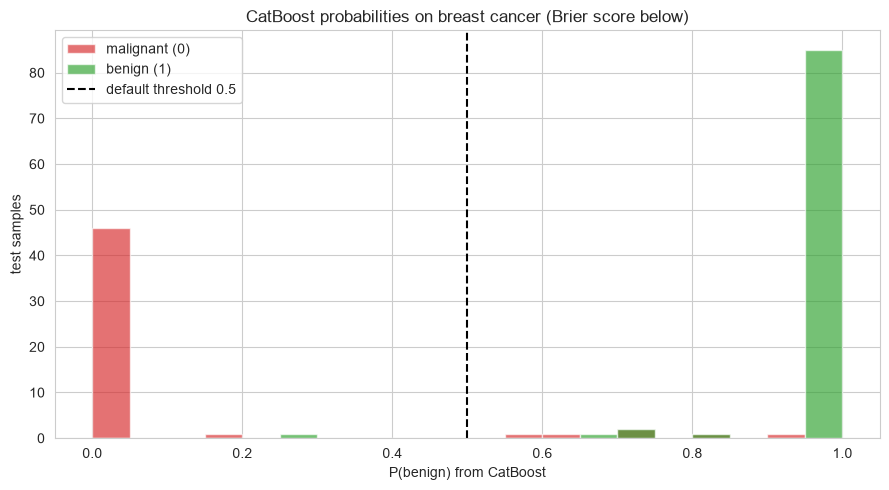

Brier score: 0.0296  (0 = perfect probabilities, 0.25 = uninformed)

💡 Same reading as notebooks 08/09/10's Example 1, one engine later: the p = 0.5
   cut is a choice. For a screening task a clinic might act at P(malignant) > 0.2,
   trading false alarms for fewer missed cancers - priced by the confusion matrix.


In [25]:
# ...and the probability read: where do the two classes' scores land?
proba_bc = final_bc_cb.predict_proba(Xbc_cb_te)[:, 1]      # P(benign)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(proba_bc[ybc_cb_te == 0], bins=np.linspace(0, 1, 21), alpha=0.65,
        color="#d62728", label="malignant (0)")
ax.hist(proba_bc[ybc_cb_te == 1], bins=np.linspace(0, 1, 21), alpha=0.65,
        color="#2ca02c", label="benign (1)")
ax.axvline(0.5, color="k", ls="--", lw=1.5, label="default threshold 0.5")
ax.set_xlabel("P(benign) from CatBoost")
ax.set_ylabel("test samples")
ax.set_title("CatBoost probabilities on breast cancer (Brier score below)")
ax.legend()
plt.tight_layout()
plt.show()

brier_bc_cbN = brier_score_loss(ybc_cb_te, proba_bc)
print(f"Brier score: {brier_bc_cbN:.4f}  (0 = perfect probabilities, 0.25 = uninformed)")
print("\n💡 Same reading as notebooks 08/09/10's Example 1, one engine later: the p = 0.5")
print("   cut is a choice. For a screening task a clinic might act at P(malignant) > 0.2,")
print("   trading false alarms for fewer missed cancers - priced by the confusion matrix.")

### Example 2: Diabetes Progression (Regression)

442 patients × 10 baseline variables (the features arrive pre-standardized), target = disease progression one year out. `CatBoostRegressor` with an ES budget; the test read is R² and RMSE, the inspection tools are PredictionValuesChange importances and the predictions-vs-truth picture.

early stopping kept tree_count_ = 115 of 1000
test R2:   0.5017
test RMSE: 52.4913


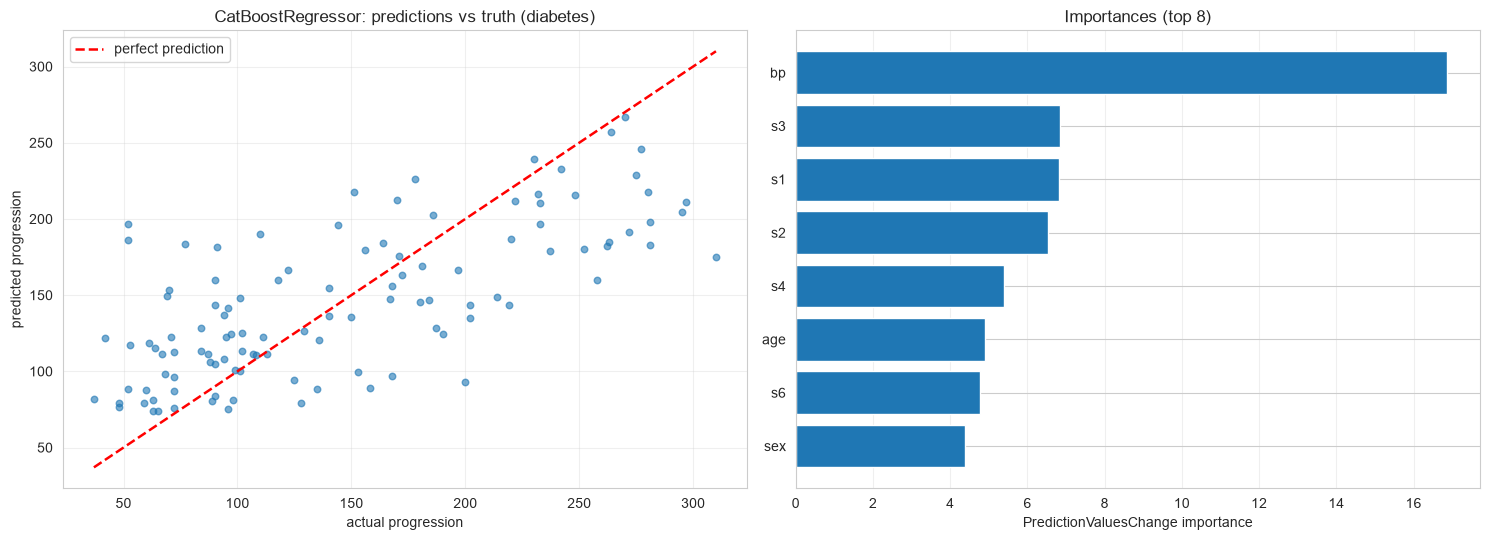


top-3 importance features: ['bmi', 's5', 'bp']

💡 The predictions clamp to the training range at the extremes - trees cannot
   extrapolate (notebook 04's warning, priced in real units here). The strongly
   correlated clinical picture from notebooks 08/09/10 reappears: importance mass
   rides on a small set of features for this small, well-conditioned regression.


In [26]:
# Example 2: diabetes progression - CatBoostRegressor with an ES budget
diabetes_cb = load_diabetes()
Xdi_cb = pd.DataFrame(diabetes_cb.data, columns=diabetes_cb.feature_names)
ydi_cb = diabetes_cb.target

Xdi_tr, Xdi_te, ydi_tr, ydi_te = train_test_split(Xdi_cb, ydi_cb, test_size=0.25,
                                                  random_state=42)
Xd_fit, Xd_val, yd_fit, yd_val = train_test_split(Xdi_tr, ydi_tr, test_size=0.2,
                                                  random_state=42)

final_di = CatBoostRegressor(depth=6, learning_rate=0.05, iterations=1000,
                             verbose=False, random_state=42)
final_di.fit(Xd_fit, yd_fit,
             eval_set=(Xd_val, yd_val),
             early_stopping_rounds=25, use_best_model=True)
pred_di = final_di.predict(Xdi_te)

print(f"early stopping kept tree_count_ = {final_di.tree_count_} of 1000")
print(f"test R2:   {r2_score(ydi_te, pred_di):.4f}")
print(f"test RMSE: {np.sqrt(mean_squared_error(ydi_te, pred_di)):.4f}")

gain_di = pd.Series(final_di.feature_importances_,
                    index=list(Xdi_cb.columns)).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(ydi_te, pred_di, alpha=0.6, s=22, color="#1f77b4")
lims_di = [min(ydi_te.min(), pred_di.min()), max(ydi_te.max(), pred_di.max())]
axes[0].plot(lims_di, lims_di, "r--", lw=1.8, label="perfect prediction")
axes[0].set_xlabel("actual progression")
axes[0].set_ylabel("predicted progression")
axes[0].set_title("CatBoostRegressor: predictions vs truth (diabetes)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].barh(gain_di.index[::-1][:8], gain_di.values[::-1][:8], color="#1f77b4")
axes[1].set_xlabel("PredictionValuesChange importance")
axes[1].set_title("Importances (top 8)")
axes[1].grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\ntop-3 importance features: {list(gain_di.head(3).index)}")
print("\n💡 The predictions clamp to the training range at the extremes - trees cannot")
print("   extrapolate (notebook 04's warning, priced in real units here). The strongly")
print("   correlated clinical picture from notebooks 08/09/10 reappears: importance mass")
print("   rides on a small set of features for this small, well-conditioned regression.")

---

## 11. Comparison with Other Algorithms

### When to Choose CatBoost vs Alternatives

| Aspect | CatBoost | XGBoost (nb 09) | LightGBM (nb 10) | HistGradientBoosting | GradientBoosting (sklearn) | Random Forest |
|---|---|---|---|---|---|---|
| **Growth policy** | oblivious: ONE condition per level | level-wise | leaf-wise, `num_leaves` budget | best-first heap, `max_leaf_nodes` | depth-limited full trees | depth-limited random subsets |
| **Split candidates** | borders over `border_count` (254) | histograms (`tree_method="hist"`) | histograms (`max_bin` 255) | histograms (`max_bins` 255) | raw value scan | raw value scan |
| **Leaf algebra** | $-G/(H+\lambda)$, λ default **3**, Newton × 10 rounds | $-G/(H+\lambda)$, λ default **1**, γ inside the gain | $-G/(H+\lambda)$, λ default **0** | Newton step (λ = 0) | Friedman tweak on the Newton step¹ | leaf means / votes |
| **Gradient estimates** | **ordered** (prefix models) ≤ 50k rows; Plain above | self (the model saw every row) | self (`goss` optional) | self | self | full-tree bagging instead |
| **Categoricals** | **ordered TS natively** + combinations | `enable_categorical` | native (`category` dtype) | `categorical_features` param | encode first | encode first |
| **NaN handling** | native (`nan_mode` Min; categories → "None") | native (learned direction) | native route | native | raises | imputation needed |
| **Row sampling** | **MVS + `subsample=0.8` by default** (Bayesian/Bernoulli/No) | `subsample` alone | `subsample` + `subsample_freq` (two keys!) | `subsample` (< 1.0) | `subsample` | bootstrap + `max_features` |
| **Column sampling** | `colsample_bylevel` per level | `colsample_bytree` per tree | `colsample_bytree` per tree | `max_features` | `max_features` | `max_features` |
| **Multiclass** | K trees per round (Plain forced) | K per stage | K trees per round | one-vs-rest internals | softmax deviance (K per stage) | vote fractions |
| **Early stopping** | `early_stopping_rounds` in fit/constructor + `eval_set` | constructor + `eval_set` | callbacks + `eval_set` | `early_stopping` param | `n_iter_no_change` trio | none (OOB instead) |
| **Default fit on small data** | Ordered auto ON + λ 3 + `random_strength` | can overfit (η 0.3, depth 6) | can overfit (num_leaves 31) | gentle | gentle (η 0.1) | very robust |
| **Speed at scale** | ⭐⭐⭐⭐ (Plain; Ordered is the slow lane) | ⭐⭐⭐⭐⭐ (hist + GPU) | ⭐⭐⭐⭐⭐ (hist + GOSS + EFB) | ⭐⭐⭐⭐ | ⭐⭐ (exact splits) | ⭐⭐⭐⭐ (parallel) |
| **Serialization** | `.cbm` (`save_model`/`load_model`, JSON export) | JSON `save_model` | `save_model` (text/JSON) | pickle-only | pickle-only | pickle-only |

¹ shared skeleton — notebook 08 §6's dual-engine analysis shows exactly where the two differ.

The **statistics-first line** is the fork CatBoost pushed: XGBoost priced the algebra, LightGBM budgeted the shape — and both still computed every gradient estimate with a model that had trained on the row it was estimating. CatBoost made the *statistics* honest (ordered TS for categories, ordered gradient estimates under 50k rows) and priced structural discipline into the defaults (oblivious shape, λ = 3, `random_strength`). Notably it is the only one of the three whose **defaults are regularized out of the box** — the "install → reasonable" argument LightGBM's tuning guide hands back to you.

### Practical Comparison

The same 5-fold CV protocol as notebooks 05/08/09/10 on three geometries. CatBoost runs `thread_count=1` (its cores belong to the outer CV sweep, same anti-thrashing arrangement as the other libraries' advice).

In [27]:
bc_cmp_cb = load_breast_cancer()
datasets_cmp = {
    "blobs (3-class)": make_blobs(n_samples=600, centers=3, cluster_std=2.0, random_state=0),
    "moons (noisy)": make_moons(n_samples=600, noise=0.25, random_state=0),
    "breast cancer": (bc_cmp_cb.data, bc_cmp_cb.target),
}


def fresh_engines():
    # CatBoost thread_count=1: the core budget belongs to cross_val_score's n_jobs=-1
    return {
        "CatBoost": CatBoostClassifier(iterations=100, learning_rate=0.1, depth=4,
                                       thread_count=1, verbose=False, random_state=0),
        "LightGBM": LGBMClassifier(num_leaves=16, learning_rate=0.1, n_estimators=100,
                                   n_jobs=1, verbosity=-1, random_state=0),
        "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                 n_jobs=1, random_state=0),
        "HistGradientBoosting": HistGradientBoostingClassifier(max_depth=3, random_state=0),
        "GradientBoosting (sklearn)": GradientBoostingClassifier(
            n_estimators=100, learning_rate=0.1, random_state=0),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
    }


cv_cmp = StratifiedKFold(5, shuffle=True, random_state=0)
rows_cmp = []
for ds_name, (X_c, y_c) in datasets_cmp.items():
    for m_name, est_c in fresh_engines().items():
        t0 = time.perf_counter()
        scores_c = cross_val_score(est_c, X_c, y_c, cv=cv_cmp,
                                   scoring="accuracy", n_jobs=-1)
        rows_cmp.append({"model": m_name, "dataset": ds_name,
                         "mean": scores_c.mean(), "std": scores_c.std(),
                         "cv time (s)": time.perf_counter() - t0})

df_cmp = pd.DataFrame(rows_cmp).pivot(index="model", columns="dataset", values="mean")
df_cmp = df_cmp[["blobs (3-class)", "moons (noisy)", "breast cancer"]]
print(df_cmp.round(3).to_string())

cb_row_cmp = df_cmp.loc["CatBoost"]
lgb_row_cmp = df_cmp.loc["LightGBM"]
xgb_row_cmp = df_cmp.loc["XGBoost"]
print(f"\nCatBoost beats its accuracy-twin XGBoost on "
      f"{int((cb_row_cmp > xgb_row_cmp).sum())} of 3 geometries;"
      f" vs LightGBM: {int((cb_row_cmp > lgb_row_cmp).sum())} of 3 (mean CV accuracy)")
times_cmp = pd.DataFrame(rows_cmp).groupby("model")["cv time (s)"].mean().round(2)
print(times_cmp.to_string())
print("\n💡 The margins are tiny and geometry-dependent - which is the honest summary:")
print("   at these sizes a well-tuned engine of this family lands within noise of any")
print("   other one, and the three-library decision is about the DATA SHAPE (categories")
print("   pay CatBoost's rent; throughput pays LightGBM's) and the defaults, not a")
print("   fixed winner. Ordered mode's auto-switch shows up in the CatBoost timings")
print("   - the prefix-model bookkeeping is real work.")

dataset                     blobs (3-class)  moons (noisy)  breast cancer
model                                                                    
CatBoost                              0.690          0.940          0.977
GradientBoosting (sklearn)            0.692          0.928          0.965
HistGradientBoosting                  0.672          0.925          0.972
LightGBM                              0.655          0.928          0.968
Random Forest                         0.637          0.925          0.967
XGBoost                               0.675          0.937          0.974

CatBoost beats its accuracy-twin XGBoost on 3 of 3 geometries; vs LightGBM: 3 of 3 (mean CV accuracy)
model
CatBoost                      0.29
GradientBoosting (sklearn)    0.36
HistGradientBoosting          0.22
LightGBM                      0.30
Random Forest                 0.52
XGBoost                       0.08

💡 The margins are tiny and geometry-dependent - which is the honest summary:
   at these

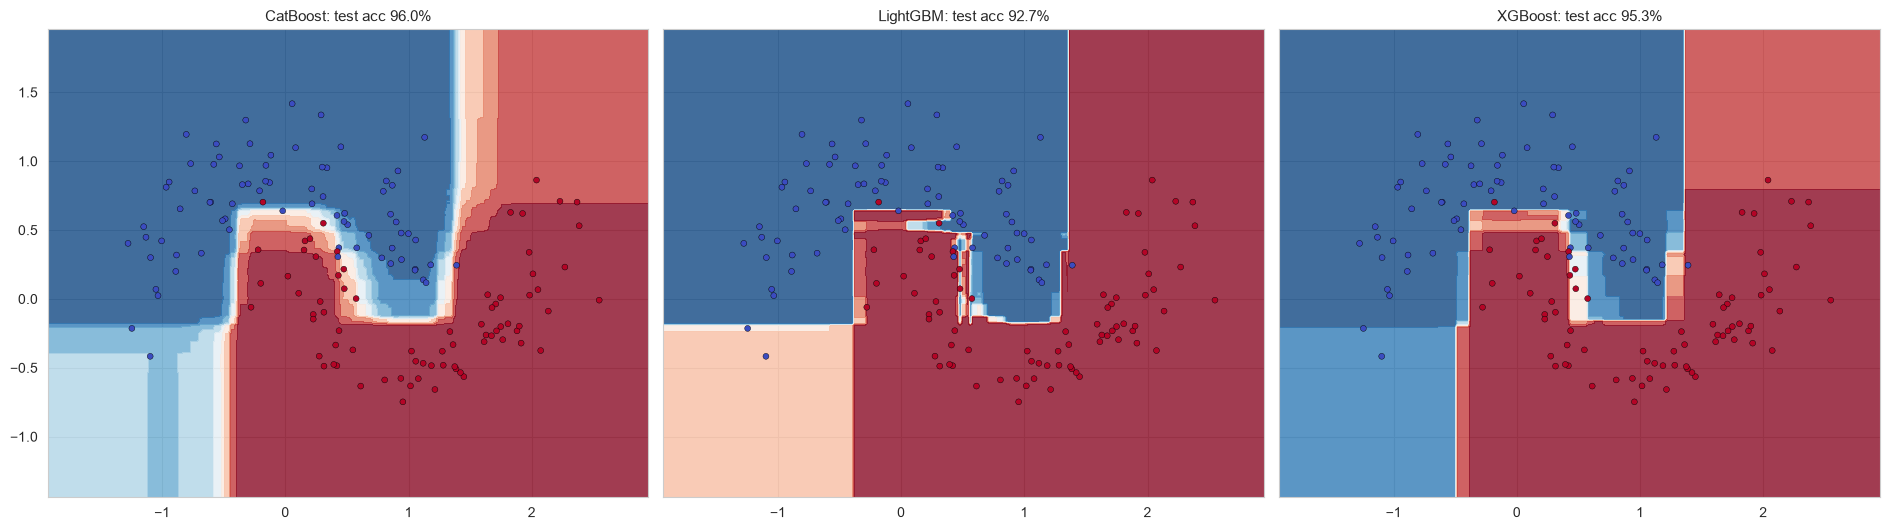


💡 Same moons, three engines of the same family: the oblivious engine's boundary
   moves in equal-depth plateaus (one condition per level), the leaf-wise engine
   cuts asymmetrically where the ridge sharpens, XGBoost's level-wise rounds the
   steps. On 350 training rows the textures differ more than the accuracies -
   the shape laws make their money when the data grows.


In [28]:
X_bd_cb, y_bd_cb = make_moons(n_samples=500, noise=0.22, random_state=42)
Xcb_bd_tr, Xcb_bd_te, ycb_bd_tr, ycb_bd_te = train_test_split(
    X_bd_cb, y_bd_cb, test_size=0.3, stratify=y_bd_cb, random_state=42)
families_bd_cb = fresh_engines()

pad_bd_cb = 0.4
xx_bd, yy_bd = np.meshgrid(
    np.linspace(X_bd_cb[:, 0].min() - pad_bd_cb, X_bd_cb[:, 0].max() + pad_bd_cb, 230),
    np.linspace(X_bd_cb[:, 1].min() - pad_bd_cb, X_bd_cb[:, 1].max() + pad_bd_cb, 230),
)
grid_bd = np.c_[xx_bd.ravel(), yy_bd.ravel()]

fig, axes_bd = plt.subplots(1, 3, figsize=(19, 5.4), sharey=True)
for ax_bd, name_bd in zip(axes_bd, ["CatBoost", "LightGBM", "XGBoost"]):
    est_bd = families_bd_cb[name_bd].fit(Xcb_bd_tr, ycb_bd_tr)
    Z_bd = est_bd.predict_proba(grid_bd)[:, 1].reshape(xx_bd.shape)
    ax_bd.contourf(xx_bd, yy_bd, Z_bd, levels=np.linspace(0.0, 1.0, 11),
                   cmap="RdBu_r", alpha=0.8)
    ax_bd.scatter(Xcb_bd_te[:, 0], Xcb_bd_te[:, 1], c=ycb_bd_te, cmap="coolwarm", s=18,
                  edgecolors="k", linewidths=0.3)
    ax_bd.set_title(f"{name_bd}: test acc {est_bd.score(Xcb_bd_te, ycb_bd_te):.1%}",
                    fontsize=11)
plt.tight_layout()
plt.show()

print("\n💡 Same moons, three engines of the same family: the oblivious engine's boundary")
print("   moves in equal-depth plateaus (one condition per level), the leaf-wise engine")
print("   cuts asymmetrically where the ridge sharpens, XGBoost's level-wise rounds the")
print("   steps. On 350 training rows the textures differ more than the accuracies -")
print("   the shape laws make their money when the data grows.")

---

## 12. References

### 📚 Academic Papers & Books

1. **Original Work**:
   — **Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). "CatBoost: Unbiased Boosting with Categorical Features."** *NeurIPS 31*: prediction shift named and measured; **ordered target statistics** (Eq. 4–5), the P1 property, and **ordered boosting** (Algorithm 1–2)
   — Dorogush, A. V., Ershov, V., & Gulin, A. (2018). "CatBoost: Gradient Boosting with Categorical Features Support." *arXiv:1810.11363*: the shipped system — the shared-structure, per-prefix leaf values, and the **power-of-two relaxation** §5 implements; CatBoost's tech-report description of structure-vs-leaf-value phases
   — Ke, G. et al. (2017). "LightGBM: A Highly Efficient Gradient Boosting Decision Tree." *NeurIPS 30*: the configurable shapes (Depthwise/Lossguide) and the histogram/border family CatBoost quantizes with borders (notebook 10)
   — Chen, T., & Guestrin, C. (2016). "XGBoost: A Scalable Tree Boosting System." *KDD '16*: the second-order regularized formulation inherited (notebook 09)
   — Friedman, J. H. (2001). "Greedy Function Approximation: A Gradient Boosting Machine." *Annals of Statistics*, 29(5): the skeleton (notebook 08)
   — Mason, L., Baxter, J., Bartlett, P., & Frean, M. (1999). "Boosting Algorithms as Gradient Descent in Function Space." *NIPS 12*: the functional-gradient view
   — Micci-Barreca, D. (2001). "A Preprocessing Scheme for High-Cardinality Categorical Attributes." *ACM SIGKDD Explorations*: the target-statistics precedent Greedy/ordered TS replace
2. **Textbooks**:
   — Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*, Chapter 10 (Boosting and Additive Trees)
   — James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An Introduction to Statistical Learning*, Chapter 8.2 (Boosting)

### 🌐 Online Resources

- [CatBoost training parameters (common)](https://catboost.ai/docs/en/references/training-parameters/common) — every parameter and default above, for the pinned version
- [CatBoostClassifier Python reference](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier) — constructor, `fit`, attributes, `get_feature_importance` types
- [Parameter tuning](https://catboost.ai/docs/en/concepts/parameter-tuning) — the official tuning order behind sections 7–9
- [Speeding up the training](https://catboost.ai/docs/en/concepts/speed-up-training) — where `Plain` and the border/bytes levers trade
- [Categorical features](https://catboost.ai/docs/en/concepts/algorithm-main-stages_cat-to-numberic) — the CTR formula this notebook hand-built
- [FAQ: Ordered memory note](https://catboost.ai/docs/en/concepts/faq) — "Ordered is set by default for datasets with less than 50 thousand objects"
- [catboost GitHub](https://github.com/catboost/catboost) — the source of the auto-learning-rate and bootstrap defaults cited here
- [StatQuest: XGBoost Parts 1–2](https://www.youtube.com/watch?v=OtD8wVaFm6E) — the shared leaf/gain mathematics, drawn

### 📊 Key Concepts to Master

- **Ordered target statistics**: per-permutation causal mean encodes; P1 (train and test statistic distributions agree); the prior/smoothing form $\hat{x} = (\mathrm{count} \cdot \bar{y} + a\,p)/(\mathrm{count} + a)$
- **Prediction shift**: gradients estimated by the model that trained on the row are biased — the disease every boosting library had, cured under 50k rows
- **The power-of-two relaxation**: $\log_2 n$ prefix models, rank $r$ reading from the first $2^{\lfloor \log_2 r \rfloor}$ rows, shared structures with per-prefix leaf values
- **Oblivious trees**: $d$ conditions, $2^d$ leaves, per-level summed-gain structure choices — a built-in shape regularizer
- **`l2_leaf_reg = 3`**: the family's λ, shipped pre-tuned instead of left at zero
- **The auto learning rate**: `learning_rate=None` resolves slow small steps for a 1000-stage budget — the factory configuration of the slow-steps lane
- **MVS by default on CPU**: sampling 0.8 of rows per stage out of the box — the stochastic damper the other libraries leave off
- **`one_hot_max_size=2`**: the boundary statistics vs one-hot ride on in the constructor

### 🔗 Related Notebooks and Repository Files

- `08_gradient_boosting.ipynb` — the skeleton (F0, residuals, staged replay) all three engines inherit
- `09_xgboost.ipynb` — the second-order leaf algebra; the λ=0 bit-for-bit check pattern this notebook reused
- `10_lightgbm.ipynb` — the leaf-budget chapter; read before this one (the lineage's middle)
- `03_decision_trees.ipynb` — the base learner and its `min_samples_leaf` (the `min_data_in_leaf` ancestor)
- `04_random_forest.ipynb` — the bagging counterpart; bootstrap-vs-MVS row sampling compared
- `16_ensemble_methods.ipynb` — stacking these engines next to linear models and forests
- `17_neural_networks_basics.ipynb` — where the unstructured-data handoff goes
- `src/models/ensemble_models.py` — `GradientBoostingClassifierScratch`, the family twin used in §5
- `tests/models/test_ensemble_models.py` — the behavioral contract of the twin

---

## Summary & Key Takeaways

### What We Learned

1. **Theory**: CatBoost keeps the family's second-order scaffold ($g$, $h$, $-G/(H+\lambda)$ — with λ shipped at 3) and rebuilds the *estimates*: ordered target statistics make categorical encodings leak-free, ordered boosting reads each row's gradient from a prefix model that never saw it
2. **Math**: the permutation $\sigma$ is the whole trick — an artificial time line so "using only the rows that came before" is well-defined offline; the power-of-two relaxation makes it $O(n)$ per stage with $\log_2 n$ auxiliary models (§5's hand loop)
3. **Shape**: oblivious trees spend $2^d$ leaves on exactly $d$ shared conditions — structure as a built-in regularizer, with `Depthwise`/`Lossguide` available where the shape itself should transplant (§2's economy table, §5's depth-1 bit-for-bit check)
4. **Assumptions**: tree-family freedom plus the machinery ones — declare your strings, keep rows exchangeable (or use `has_time`), match the loss and metric to the decision (§3's two demos)
5. **Implementation**: the family twin carries the shared skeleton; the ordered-TS encoder, the oblivious grower (dual pricing), and the prefix-model ordered loop were hand-built on it in NumPy (§5)
6. **Interfaces**: the sklearn wrapper (native + alias names in one constructor, `verbose=False`, `early_stopping_rounds` + `eval_set`, `use_best_model`) and the native reads (`Pool`, `get_feature_importance` types, `staged_predict`, `.cbm` artifacts) (§6)
7. **Hyperparameters**: `depth` first (2^depth leaves), `l2_leaf_reg` second (shipped 3), η × iterations third (auto-lr covers the default regime), `boosting_type` Ordered/Plain (auto-switch at 50k), sampling last (MVS already on) — CV-only tuning, one test read (§7)
8. **Practice**: the chapter's cost ledger — Ordered buys small-data honesty with time; the label-poles demo is the leak, personified; a native engine assigns ~zero importance to a noise category the greedy encoding would banquet on (§3, §6)

### When to Use CatBoost

✅ **Use when**:
- the table has real declared categoricals — ordered statistics + combinations are the engine's rent, paid back on consumer-grade tuning time
- the data is small-to-medium (≤ ~50k rows) — the auto-Ordered default exists for exactly that range
- defaults matter more than a tuning session — the pre-regularized (`l2_leaf_reg` 3, `random_strength` 1, oblivious shape) install
- regression too — RMSE to MAE/Quantile/Huber/Poisson with the same machinery

❌ **Avoid when**:
- millions of rows and training time is the product — Ordered's bookkeeping is the slow lane; `Plain` recovers most of it, LightGBM keeps the throughput crown
- a few hundred rows with untouched defaults — shrink `depth`, or a linear model is steadier (notebook 01)
- extrapolation is required — trees clamp to the training range (§10's Example 2)
- every leaf must be walked for an audit — SHAP/Interaction explain in aggregate; `plot_tree` needs graphviz

### Best Practices Checklist

- ✅ declare categoricals in the constructor; keep `one_hot_max_size`'s default honest boundary in mind
- ✅ `verbose=False` in batch work; note the `catboost_info/` folder (`allow_writing_files=False` if the repo must stay clean)
- ✅ `depth` before everything else on small data (3–4), `l2_leaf_reg` up when the gap yawns
- ✅ early stop with `eval_set` + `early_stopping_rounds` + `use_best_model=True`; CV for knobs, one test read
- ✅ `thread_count=1` for the estimator inside parallel sklearn sweeps
- ✅ read importances + SHAP, verify removals with `permutation_importance`
- ✅ `random_state` fixed for any comparison; `bootstrap_type="No"` + `random_strength=0` when a run must be bit-exact

### Critical Requirements

1. **Declared categoricals or numeric data** — strings undeclared are a loud error; declared NaNs become the "None" category
2. **A loss and metric that match the task** — objective inferred by the wrapper class, `eval_metric` your call and the ES driver
3. **Exchangeable rows** for the permutation machinery — temporal drift needs `has_time` or deliberate splits
4. **Enough rows per oblivious level** — 2^depth leaves want evidence; the min_data_in_leaf floor and the shipped λ both pitch in

### Advantages vs Disadvantages

**Advantages:**
- ✅ native, leak-resistant categorical handling with cross-feature combinations in the box
- ✅ ordered gradient estimates on the small-data regime where classic boosting self-overfits fastest
- ✅ pre-regularized defaults (λ 3, `random_strength`, symmetric shape, MVS sampling) — the family's least-tuned, most-sane install
- ✅ portable `.cbm` artifacts and a rich introspection surface (borders, SHAP, interactions, stage replay)

**Disadvantages:**
- ❌ the slowest of the three libraries under its default Ordered mode; throughput requires the `Plain` switch
- ❌ the auto learning rate + 1000-iteration defaults are a long-game budget — small-data sweeps re-spec them anyway
- ❌ no trees_to_dataframe-style structure read without graphviz for `plot_tree` — structural debugging is importances + SHAP, not walks
- ❌ `cat_features` declaration and NaN semantics ("None" categories vs routed float NaNs) are quirks to memorize

### Unique Characteristic: The Ordered Estimator

XGBoost priced the algebra, LightGBM budgeted the shape; **CatBoost made the statistics honest** — every estimate a row contributes to its own fit subtracts its own target first, from the categorical encodings to the gradient table itself. The one sentence to remember: **no row grades its own homework — order the data, price the leaves with λ = 3, ship the statistic the test rows could also receive.**

### Next Steps

1. **Practice** the recipes on your own data: declare categoricals, depth down on small tables, `l2_leaf_reg` as the first lever, ES everywhere (§7's order)
2. **Diagnose** with `evals_result_` curves, `get_feature_importance` types, `get_borders()`, and SHAP contributions on suspicious rows
3. **Compare** against XGBoost and LightGBM on the same folds (§11's harness) — and against a random forest when no categories pay the rent
4. **Read** notebook 16 next for the stacked-ensembles view, or 17 to see where the classical stack hands off
5. **Explore** `src/models/ensemble_models.py` — the twin behind §5, whose Newton leaf is exactly this family's λ = 0 leaf, and the file whose API the whole app is built around

---

**Congratulations!** You can now order a permutation, walk it causally, price a level-shared split, distinguish Ordered from Plain on sight — and you know exactly why a no-signal 150-category column earns near-zero importance in one encoding and a leak-fueled acc bonus in another. 🎯🎉

**Remember**: the model is a permutation plus a cascade of honest statistics. Declare the categories, let the prior speak until evidence accumulates, keep λ = 3 between the leaves and the noise — and never let a row vote on itself. 🐱